# Generate the shared local-$n_K$ profile

These cells generate the energy-conserving profile used by both figures below. The physical inputs are $T_N=10\,\mathrm{MeV}$, $n_{B,N}=3n_0$, and $B^{1/4}=180\,\mathrm{MeV}$. A short continuation in the local interface fraction reaches the calibrated endpoint $a_{Q^*}=0.5483538$, for which $T_{Q^*}\simeq3\,\mathrm{MeV}$. The generated table is stored under `local_analysis_results/All_Plots_new/`, not `csv_share/`.


In [1]:
# Tunable profile-generation parameters
LOCAL_PROFILE_CSV = "local_analysis_results/All_Plots_new/energy_conserving_nK_TN10_TQstar3_nBN3n0_B180.csv"
T_N = 10.0
N_B_N_OVER_N0 = 3.0
B_ONE_FOURTH_MEV = 180.0
A_QSTAR_TARGET = 0.538
T_QSTAR_TARGET = 7.0
T_QSTAR_TOLERANCE = 0.01
A_QSTAR_TOLERANCE = 5.0e-6
AQSTAR_CONTINUATION = (0.400, 0.42, 0.44, 0.460, A_QSTAR_TARGET)
TAIL_EPS = 1.0e-3
N_MESH = 40
TOL_BVP = 1.0e-4
MAX_NODES = 5000
INITIAL_JB_GUESS = 1.73935
JB_BOUNDS = (1.0e-4, 5.0)
M_S = 0.0
NM_TYPE = "PNM"
N0_FM3 = 0.16

import importlib
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
import RMFsolver.phase_velocity as phase_velocity

phase_velocity = importlib.reload(phase_velocity)
LOCAL_PROFILE_CSV = Path(LOCAL_PROFILE_CSV)
n0_mev3 = N0_FM3 * const.MeV_fm**3
nB_N = N_B_N_OVER_N0 * n0_mev3
LOCAL_PROFILE_CSV.parent.mkdir(parents=True, exist_ok=True)


In [2]:
continuation_rows = []
profile_seed = None

for stage_aQstar in AQSTAR_CONTINUATION:
    stage_result = phase_velocity._solve_front_energy_conserving_nK_once(
        T_0minus=T_N,
        nB_0minus=nB_N,
        B_one_forth=B_ONE_FOURTH_MEV,
        a_0plus=stage_aQstar,
        ms=M_S,
        param=para.paraQMCRMF3,
        NM_type=NM_TYPE,
        tail_eps=TAIL_EPS,
        compact_scale=None if profile_seed is None else profile_seed["compact_scale"],
        n_mesh=N_MESH,
        tol_bvp=TOL_BVP,
        max_nodes=MAX_NODES,
        jB_guess=INITIAL_JB_GUESS if profile_seed is None else profile_seed["jB"],
        jB_bounds=JB_BOUNDS,
        return_profile=True,
        return_raw_bvp_grid=False,
        verb=False,
        profile_guess=profile_seed,
    )
    if not bool(stage_result.get("success")):
        raise RuntimeError(
            f"Local-nK continuation failed at aQstar={stage_aQstar:.7f}: "
            f"{stage_result.get('message')}"
        )

    continuation_rows.append(
        {
            "aQstar": float(stage_aQstar),
            "T_Qstar_MeV": float(stage_result["T_profile"][0]),
            "jB": float(stage_result["jB"]),
            "bvp_nodes": int(stage_result["bvp_nodes"]),
        }
    )
    profile_seed = stage_result

profile_result = profile_seed
T_QSTAR_ACTUAL = float(profile_result["T_profile"][0])
A_QSTAR_ACTUAL = float(profile_result["a"][0])


P_N = float(phase_velocity.PNM_n(nB_N, T_N, param=para.paraQMCRMF3, NM_type=NM_TYPE))
e_N = float(phase_velocity.edensNM_n(nB_N, T_N, param=para.paraQMCRMF3))
h_N = P_N + e_N

upstream_profile = pd.DataFrame(
    [
        {
            "dummy": 0.0,
            "x": 0.0,
            "a": 1.0,
            "u": float(profile_result["u_0minus"]),
            "P": P_N,
            "e": e_N,
            "h": h_N,
            "nB": nB_N,
            "nK": nB_N,
            "muB": np.nan,
            "muK": np.nan,
            "T": T_N,
            "h_over_nB": h_N / nB_N,
            "P_over_e": P_N / e_N,
            "D": np.nan,
            "gamma": np.nan,
            "eta": np.nan,
        }
    ]
)

quark_energy_density = profile_result["h_profile"] - profile_result["P_profile"]
quark_profile = pd.DataFrame(
    {
        "dummy": np.zeros_like(profile_result["x"]),
        "x": profile_result["x"],
        "a": profile_result["a"],
        "u": profile_result["u"],
        "P": profile_result["P_profile"],
        "e": quark_energy_density,
        "h": profile_result["h_profile"],
        "nB": profile_result["nB"],
        "nK": profile_result["nK"],
        "muB": profile_result["muB"],
        "muK": profile_result["muK"],
        "T": profile_result["T_profile"],
        "h_over_nB": profile_result["h_profile"] / profile_result["nB"],
        "P_over_e": profile_result["P_profile"] / quark_energy_density,
        "D": 1.0 / profile_result["invD_profile"],
        "gamma": np.full_like(profile_result["x"], np.nan),
        "eta": np.full_like(profile_result["x"], np.nan),
    }
)

generated_profile = pd.concat(
    [upstream_profile, quark_profile],
    ignore_index=True,
)
generated_profile.to_csv(LOCAL_PROFILE_CSV, index=False)

display(pd.DataFrame(continuation_rows))
print(f"Saved local profile: {LOCAL_PROFILE_CSV}")
print(f"T_N = {T_N:.6f} MeV")
print(f"nB_N/n0 = {nB_N / n0_mev3:.6f}")
print(f"a_N = {upstream_profile['a'].iloc[0]:.6f}")
print(f"a_Qstar = {A_QSTAR_ACTUAL:.7f}")
print(f"T_Qstar = {T_QSTAR_ACTUAL:.6f} MeV")
print(f"T_Qstar target = {T_QSTAR_TARGET:.6f} MeV")
print(f"T_Qstar actual = {T_QSTAR_ACTUAL:.6f} MeV")


,aQstar,T_Qstar_MeV,jB,bvp_nodes
0,0.400,22.223397,0.775695,51
1,0.420,20.948319,0.845111,50
2,0.440,19.511532,0.922891,50
3,0.460,17.872230,1.011915,49
4,0.538,6.990575,1.693105,93


Saved local profile: local_analysis_results/All_Plots_new/energy_conserving_nK_TN10_TQstar3_nBN3n0_B180.csv
T_N = 10.000000 MeV
nB_N/n0 = 3.000000
a_N = 1.000000
a_Qstar = 0.5380000
T_Qstar = 6.990575 MeV
T_Qstar target = 7.000000 MeV
T_Qstar actual = 6.990575 MeV


# Representative energy-conserving front profile

The four panels show the composition variable $a$, fluid velocity $u$, temperature $T$, and baryon density $n_B$ across one representative conversion front. The dashed segment at $x<0$ is the uniform upstream nuclear-matter state, the solid segment at $x>0$ is the quark-matter conversion layer, and the thin vertical line marks the interface at $x=0$.


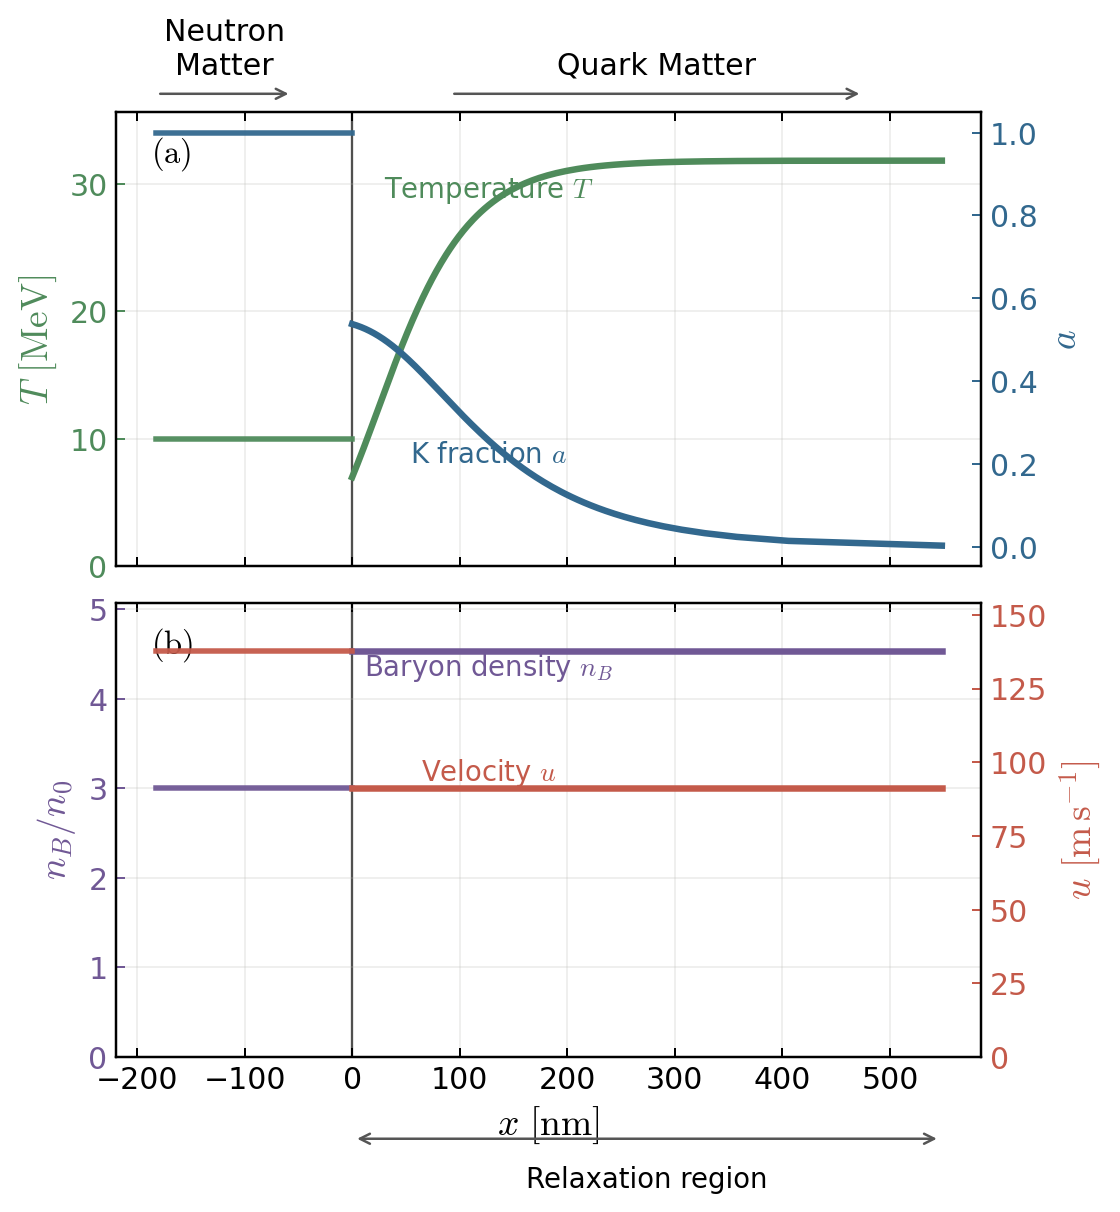

Profile: local_analysis_results/All_Plots_new/energy_conserving_nK_TN10_TQstar3_nBN3n0_B180.csv
Upstream span: -182.74 to 0 in plotted x units
Quark span: 0 to 548.219 in plotted x units
Saved: Latex_writting/Hydrodynamical combustion/Plots/Example_profile.pdf


In [3]:
# Tunable plotting parameters
PROFILE_CSV = "local_analysis_results/All_Plots_new/energy_conserving_nK_TN10_TQstar3_nBN3n0_B180.csv"
OUTPUT_PDF = "Latex_writting/Hydrodynamical combustion/Plots/Example_profile.pdf"
FIGURE_SIZE = (6.2, 7.0)
FIGURE_DPI = 180
EXPORT_DPI = 350
AXIS_LABEL_FONT_SIZE = 15
TICK_LABEL_FONT_SIZE = 12
CURVE_LABEL_FONT_SIZE = 11
PHASE_LABEL_FONT_SIZE = 12
PANEL_LABEL_FONT_SIZE = 13
RELAXATION_FONT_SIZE = 11
LINE_WIDTH = 2.6
UPSTREAM_LINE_WIDTH = 2.2
INTERFACE_LINE_WIDTH = 0.9
SPINE_LINE_WIDTH = 0.9
GRID_LINE_WIDTH = 0.7
UPSTREAM_LINE_STYLE = "-"
INTERFACE_LINE_STYLE = "-"
A_COLOR = "#32688E"
U_COLOR = "#C45A4A"
T_COLOR = "#4F8B5B"
NB_COLOR = "#705895"
INTERFACE_COLOR = "#353535"
GRID_COLOR = "#B8B8B3"
GRID_ALPHA = 0.24
UPSTREAM_ALPHA = 0.95
TICK_DIRECTION = "in"
PHASE_LABEL_NM = "Neutron\nMatter"
PHASE_LABEL_QM = "Quark Matter"
RELAXATION_LABEL = "Relaxation region"
RELAXATION_BRACKET_Y = -0.18
SHOW_GRID = True
PANEL_LABELS = (r"$\mathrm{(a)}$", r"$\mathrm{(b)}$")
PANEL_LABEL_POSITIONS = ((0.04, 0.95), (0.04, 0.95))
T_Y_HEADROOM_FACTOR = 1.12
NB_Y_HEADROOM_FACTOR = 1.12
U_Y_HEADROOM_FACTOR = 1.12
SUBPLOT_HSPACE = 0.08
SUBPLOT_TOP = 0.86
UPSTREAM_WIDTH_FRACTION = 1.0 / 3.0
UPSTREAM_A_FRACTION = 1.0
SPEED_OF_LIGHT_M_S = 299792458.0
NUCLEAR_DENSITY_FM3 = 0.16
HBARC_MEV_FM = 197.326960
FM_PER_NM = 1.0e6
X_AXIS_LABEL = r"$x\ [\mathrm{nm}]$"
T_AXIS_LABEL = r"$T\ [\mathrm{MeV}]$"
A_AXIS_LABEL = r"$a$"
NB_AXIS_LABEL = r"$n_B/n_0$"
U_AXIS_LABEL = r"$u\ [\mathrm{m\,s}^{-1}]$"
T_CURVE_LABEL = r"Temperature $T$"
A_CURVE_LABEL = r"K fraction $a$"
NB_CURVE_LABEL = r"Baryon density $n_B$"
U_CURVE_LABEL = r"Velocity $u$"
SAVE_TRANSPARENT = False
BOUNDING_BOX = "tight"

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

profile_path = Path(PROFILE_CSV)
output_pdf_path = Path(OUTPUT_PDF)
output_pdf_path.parent.mkdir(parents=True, exist_ok=True)

data = pd.read_csv(profile_path)
upstream_rows = data.loc[~np.isfinite(data["D"])].copy()
quark_profile = data.loc[np.isfinite(data["D"])].copy().sort_values("x")

if upstream_rows.empty:
    raise RuntimeError("No upstream nuclear-matter row found")
if quark_profile.empty:
    raise RuntimeError("No finite-D quark-matter profile found")

upstream = upstream_rows.iloc[0]
x_quark = (
    quark_profile["x"].to_numpy(dtype=float)
    * HBARC_MEV_FM
    / FM_PER_NM
)
x_quark = x_quark - x_quark[0]
x_quark_max = float(np.max(x_quark))
x_upstream = np.array([-UPSTREAM_WIDTH_FRACTION * x_quark_max, 0.0])
n0_mev3 = NUCLEAR_DENSITY_FM3 * HBARC_MEV_FM**3

T_values = quark_profile["T"].to_numpy(dtype=float)
a_values = quark_profile["a"].to_numpy(dtype=float)
nB_values = quark_profile["nB"].to_numpy(dtype=float) / n0_mev3
u_values = SPEED_OF_LIGHT_M_S * quark_profile["u"].to_numpy(dtype=float)

T_upstream = float(upstream["T"])
a_upstream = UPSTREAM_A_FRACTION
nB_upstream = float(upstream["nB"]) / n0_mev3
u_upstream = SPEED_OF_LIGHT_M_S * float(upstream["u"])

mpl.rcParams.update(
    {
        "mathtext.fontset": "cm",
        "mathtext.rm": "serif",
        "mathtext.it": "serif:italic",
        "mathtext.bf": "serif:bold",
    }
)

fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=FIGURE_SIZE, dpi=FIGURE_DPI, sharex=True
)
ax_top_r = ax_top.twinx()
ax_bot_r = ax_bot.twinx()

# ── Top panel: T (left, green) and a (right, blue) ──────────────────────────
ax_top.axvline(0.0, color=INTERFACE_COLOR, linewidth=INTERFACE_LINE_WIDTH,
               linestyle=INTERFACE_LINE_STYLE, zorder=0)

ax_top.plot(x_upstream, np.full_like(x_upstream, T_upstream),
            color=T_COLOR, linewidth=UPSTREAM_LINE_WIDTH,
            linestyle=UPSTREAM_LINE_STYLE, alpha=UPSTREAM_ALPHA)
ax_top.plot(x_quark, T_values, color=T_COLOR, linewidth=LINE_WIDTH)
ax_top.set_ylabel(T_AXIS_LABEL, fontsize=AXIS_LABEL_FONT_SIZE, color=T_COLOR)
ax_top.tick_params(axis="y", colors=T_COLOR)
ax_top.set_ylim(0.0, T_Y_HEADROOM_FACTOR * max(T_upstream, np.max(T_values)))

ax_top_r.plot(x_upstream, np.full_like(x_upstream, a_upstream),
              color=A_COLOR, linewidth=UPSTREAM_LINE_WIDTH,
              linestyle=UPSTREAM_LINE_STYLE, alpha=UPSTREAM_ALPHA)
ax_top_r.plot(x_quark, a_values, color=A_COLOR, linewidth=LINE_WIDTH)
ax_top_r.set_ylabel(A_AXIS_LABEL, fontsize=AXIS_LABEL_FONT_SIZE, color=A_COLOR)
ax_top_r.tick_params(axis="y", colors=A_COLOR)

# Curve labels — placed at 80% along quark profile
label_x_frac = 0.80
label_idx = int(label_x_frac * (len(x_quark) - 1))
ax_top.text(x_quark[label_idx], T_values[label_idx], T_CURVE_LABEL,
            color=T_COLOR, va="bottom", ha="center", fontsize=CURVE_LABEL_FONT_SIZE)
ax_top_r.text(x_quark[label_idx], a_values[label_idx], A_CURVE_LABEL,
              color=A_COLOR, va="top", ha="center", fontsize=CURVE_LABEL_FONT_SIZE)

# ── Bottom panel: nB (left, purple) and u (right, red) ──────────────────────
ax_bot.axvline(0.0, color=INTERFACE_COLOR, linewidth=INTERFACE_LINE_WIDTH,
               linestyle=INTERFACE_LINE_STYLE, zorder=0)

ax_bot.plot(x_upstream, np.full_like(x_upstream, nB_upstream),
            color=NB_COLOR, linewidth=UPSTREAM_LINE_WIDTH,
            linestyle=UPSTREAM_LINE_STYLE, alpha=UPSTREAM_ALPHA)
ax_bot.plot(x_quark, nB_values, color=NB_COLOR, linewidth=LINE_WIDTH)
ax_bot.set_ylabel(NB_AXIS_LABEL, fontsize=AXIS_LABEL_FONT_SIZE, color=NB_COLOR)
ax_bot.tick_params(axis="y", colors=NB_COLOR)
ax_bot.set_ylim(0.0, NB_Y_HEADROOM_FACTOR * max(nB_upstream, np.max(nB_values)))

ax_bot_r.plot(x_upstream, np.full_like(x_upstream, u_upstream),
              color=U_COLOR, linewidth=UPSTREAM_LINE_WIDTH,
              linestyle=UPSTREAM_LINE_STYLE, alpha=UPSTREAM_ALPHA)
ax_bot_r.plot(x_quark, u_values, color=U_COLOR, linewidth=LINE_WIDTH)
ax_bot_r.set_ylabel(U_AXIS_LABEL, fontsize=AXIS_LABEL_FONT_SIZE, color=U_COLOR)
ax_bot_r.tick_params(axis="y", colors=U_COLOR)
ax_bot_r.set_ylim(0.0, U_Y_HEADROOM_FACTOR * max(u_upstream, np.max(u_values)))

# Curve labels
ax_bot.text(x_quark[label_idx], nB_values[label_idx], NB_CURVE_LABEL,
            color=NB_COLOR, va="top", ha="center", fontsize=CURVE_LABEL_FONT_SIZE)
ax_bot_r.text(x_quark[label_idx], u_values[label_idx], U_CURVE_LABEL,
              color=U_COLOR, va="bottom", ha="center", fontsize=CURVE_LABEL_FONT_SIZE)

# ── Phase labels and flow arrows above the top panel ─────────────────────────
x_interface_frac = UPSTREAM_WIDTH_FRACTION / (1.0 + UPSTREAM_WIDTH_FRACTION)
arrow_kw = dict(arrowstyle="->", color="#555555", lw=1.0)

ax_top.text(
    x_interface_frac * 0.5, 1.07, PHASE_LABEL_NM,
    transform=ax_top.transAxes,
    fontsize=PHASE_LABEL_FONT_SIZE,
    ha="center", va="bottom",
)
ax_top.annotate(
    "", xy=(x_interface_frac * 0.82, 1.04), xytext=(x_interface_frac * 0.18, 1.04),
    xycoords="axes fraction", textcoords="axes fraction",
    arrowprops=arrow_kw,
    annotation_clip=False,
)
ax_top.text(
    x_interface_frac + (1.0 - x_interface_frac) * 0.5, 1.07, PHASE_LABEL_QM,
    transform=ax_top.transAxes,
    fontsize=PHASE_LABEL_FONT_SIZE,
    ha="center", va="bottom",
)
ax_top.annotate(
    "",
    xy=(x_interface_frac + (1.0 - x_interface_frac) * 0.82, 1.04),
    xytext=(x_interface_frac + (1.0 - x_interface_frac) * 0.18, 1.04),
    xycoords="axes fraction", textcoords="axes fraction",
    arrowprops=arrow_kw,
    annotation_clip=False,
)

# ── Relaxation region bracket below bottom panel ─────────────────────────────
brac_y = RELAXATION_BRACKET_Y
ax_bot.annotate(
    "", xy=(x_quark_max, brac_y), xytext=(0.0, brac_y),
    xycoords=("data", "axes fraction"),
    textcoords=("data", "axes fraction"),
    arrowprops=dict(arrowstyle="<->", color="#555555", lw=1.0),
    annotation_clip=False,
)
ax_bot.text(
    x_quark_max / 2.0, brac_y - 0.06, RELAXATION_LABEL,
    transform=mpl.transforms.blended_transform_factory(
        ax_bot.transData, ax_bot.transAxes
    ),
    ha="center", va="top", fontsize=RELAXATION_FONT_SIZE, clip_on=False,
)

# ── Ticks, spines, grid, panel labels ────────────────────────────────────────
for ax_left, ax_right, label, pos in zip(
    (ax_top, ax_bot),
    (ax_top_r, ax_bot_r),
    PANEL_LABELS,
    PANEL_LABEL_POSITIONS,
):
    ax_left.text(
        *pos, label, transform=ax_left.transAxes,
        fontsize=PANEL_LABEL_FONT_SIZE, va="top", ha="left",
    )
    ax_left.tick_params(
        which="both", direction=TICK_DIRECTION,
        top=True, labelsize=TICK_LABEL_FONT_SIZE,
    )
    ax_right.tick_params(
        which="both", direction=TICK_DIRECTION,
        top=False, labelsize=TICK_LABEL_FONT_SIZE,
    )
    for ax in (ax_left, ax_right):
        for spine in ax.spines.values():
            spine.set_linewidth(SPINE_LINE_WIDTH)
    if SHOW_GRID:
        ax_left.grid(color=GRID_COLOR, linewidth=GRID_LINE_WIDTH, alpha=GRID_ALPHA)
        ax_right.grid(False)

ax_bot.set_xlabel(X_AXIS_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)

fig.subplots_adjust(hspace=SUBPLOT_HSPACE, top=SUBPLOT_TOP)

fig.savefig(
    output_pdf_path, dpi=EXPORT_DPI, bbox_inches=BOUNDING_BOX,
    transparent=SAVE_TRANSPARENT,
)
plt.show()

print(f"Profile: {profile_path}")
print(f"Upstream span: {x_upstream[0]:.6g} to 0 in plotted x units")
print(f"Quark span: 0 to {x_quark_max:.6g} in plotted x units")
print(f"Saved: {output_pdf_path}")


# Constant-pressure trajectory in the $(a,T)$ plane

This figure compares an energy-conserving numerical front profile with the quarter-ellipse obtained by treating $P$, $\mu_B$, and $n_B$ as constant through the conversion layer. The plotting style follows the older $(\mu_B,\mu_K)$-plane figure in `All_Plots.ipynb`.

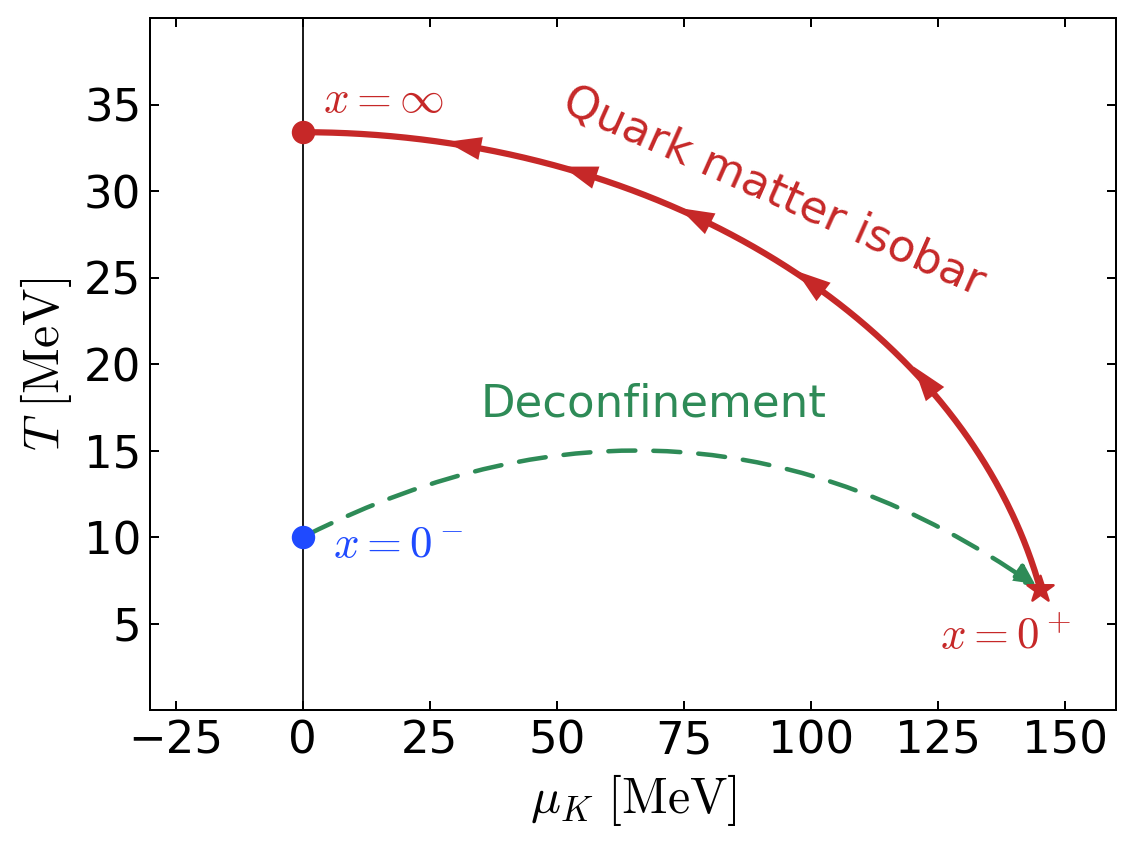

Profile: local_analysis_results/All_Plots_new/energy_conserving_nK_TN10_TQstar3_nBN3n0_B180.csv
T(0-) = 10.000000 MeV
T(0+) = 6.990575 MeV
T(infinity, schematic isobar) = 33.400874 MeV
muK(0+) = 145.109635 MeV
Nuclear marker is placed at muK=0 and does not indicate a nuclear muK trajectory
Saved: Latex_writting/Hydrodynamical combustion/Plots/Sketch_T_muK_plane.pdf


In [4]:
# Tunable plotting parameters
PROFILE_CSV = "local_analysis_results/All_Plots_new/energy_conserving_nK_TN10_TQstar3_nBN3n0_B180.csv"
OUTPUT_PDF = "Latex_writting/Hydrodynamical combustion/Plots/Sketch_T_muK_plane.pdf"
FIGURE_SIZE = (6.4, 4.8)
FIGURE_DPI = 180
EXPORT_DPI = 300
AXIS_LABEL_FONT_SIZE = 20
TICK_LABEL_FONT_SIZE = 18
ANNOTATION_FONT_SIZE = 18
PHASE_LABEL_FONT_SIZE = 18
LINE_WIDTH = 2.5
ARROW_LINE_WIDTH = 1.8
ARROW_MUTATION_SCALE = 18
QUIVER_WIDTH = 0.003
QUIVER_HEAD_WIDTH = 8
QUIVER_HEAD_LENGTH = 12
MARKER_SIZE = 70
INTERFACE_MARKER_SIZE = 120
MARKER_ZORDER = 5
QUARK_COLOR = "#c62828"
NUCLEAR_COLOR = "#1f4aff"
CROSSING_COLOR = "#2e8b57"
ISOBAR_LINE_STYLE = "-"
CROSSING_LINE_STYLE = (0, (6, 4))
GRID_POINTS = 400
QUARK_ARROW_COUNT = 5
QUARK_ARROW_LENGTH = 8.0
NUCLEAR_MARKER_MUK = 0.0
X_LIMITS = (-30.0, 160.0)
Y_LIMITS = (0.0, 40.0)
X_TICKS = (-25.0, 0.0, 25.0, 50.0, 75.0, 100.0, 125.0, 150.0)
Y_TICKS = (0.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 35.0)
TICK_DIRECTION = "in"
SHOW_TOP_TICKS = True
SHOW_RIGHT_TICKS = True
X_AXIS_LABEL = r"$\mu_K\ \mathrm{[MeV]}$"
Y_AXIS_LABEL = r"$T\ \mathrm{[MeV]}$"
NUCLEAR_PHASE_LABEL = "Nuclear matter side"
QUARK_ISOBAR_LABEL = "Quark matter isobar"
CROSSING_LABEL = "Deconfinement"
NUCLEAR_ENDPOINT_LABEL = r"$x=0^-$"
INTERFACE_ENDPOINT_LABEL = r"$x=0^+$"
DOWNSTREAM_ENDPOINT_LABEL = r"$x=\infty$"
NUCLEAR_NOTE_LABEL = r"$T(0^-)=10\ \mathrm{MeV}$"
NUCLEAR_LABEL_POSITION = (8.0, 12.0)
NUCLEAR_NOTE_POSITION = (8.0, 7.6)
QUARK_LABEL_POSITION = (50.0, 24.0)
QUARK_LABEL_ROTATION = -24.0
CROSSING_LABEL_POSITION = (35.0, 17.0)
CROSSING_LABEL_ROTATION = 0.0
NUCLEAR_ENDPOINT_OFFSET = (12, -8)
INTERFACE_ENDPOINT_OFFSET = (-40, -24)
DOWNSTREAM_ENDPOINT_OFFSET = (8, 8)
SHOW_GRID = False
GRID_ALPHA = 0.15
AXIS_LINE_COLOR = "black"
AXIS_LINE_WIDTH = 0.7
SAVE_TRANSPARENT = False
BOUNDING_BOX = "tight"

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import FancyArrowPatch

profile_path = Path(PROFILE_CSV)
output_pdf_path = Path(OUTPUT_PDF)
output_pdf_path.parent.mkdir(parents=True, exist_ok=True)

data = pd.read_csv(profile_path)
upstream = data[data["D"].isna()].iloc[0]
profile = data[data["D"].notna()].copy().sort_values("muK")
qstar = profile.iloc[-1]

nuclear_T = float(upstream["T"])
interface_muK = float(qstar["muK"])
interface_T = float(qstar["T"])

# Draw a schematic constant-muB quark isobar through x=0+ and x=infinity.
# The blue nuclear point is placed at muK=0 to avoid implying a nuclear muK trajectory.
downstream_T = np.sqrt(interface_T**2 + interface_muK**2 / (2.0 * np.pi**2))
muK_isobar = np.linspace(0.0, interface_muK, GRID_POINTS)
T_isobar = np.sqrt(np.maximum(downstream_T**2 - muK_isobar**2 / (2.0 * np.pi**2), 0.0))

downstream_muK = 0.0
nuclear_marker_muK = NUCLEAR_MARKER_MUK

mpl.rcParams.update(
    {
        "mathtext.fontset": "cm",
        "mathtext.rm": "serif",
        "mathtext.it": "serif:italic",
        "mathtext.bf": "serif:bold",
    }
)

fig, ax = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI)

ax.axhline(0.0, color=AXIS_LINE_COLOR, linewidth=AXIS_LINE_WIDTH)
ax.axvline(0.0, color=AXIS_LINE_COLOR, linewidth=AXIS_LINE_WIDTH)

ax.plot(
    muK_isobar,
    T_isobar,
    color=QUARK_COLOR,
    linewidth=LINE_WIDTH,
    linestyle=ISOBAR_LINE_STYLE,
)

arrow_muK = np.linspace(interface_muK * 0.88, interface_muK * 0.25, QUARK_ARROW_COUNT)
arrow_T = np.sqrt(np.maximum(downstream_T**2 - arrow_muK**2 / (2.0 * np.pi**2), 0.0))
dT_dmuK = -arrow_muK / (2.0 * np.pi**2 * arrow_T)
tangent_norm = np.sqrt(1.0 + dT_dmuK**2)
arrow_u = -QUARK_ARROW_LENGTH / tangent_norm
arrow_v = -QUARK_ARROW_LENGTH * dT_dmuK / tangent_norm
ax.quiver(
    arrow_muK,
    arrow_T,
    arrow_u,
    arrow_v,
    angles="xy",
    scale_units="xy",
    scale=1,
    color=QUARK_COLOR,
    width=QUIVER_WIDTH,
    headwidth=QUIVER_HEAD_WIDTH,
    headlength=QUIVER_HEAD_LENGTH,
    headaxislength=QUIVER_HEAD_LENGTH,
)

crossing_arrow = FancyArrowPatch(
    (nuclear_marker_muK, nuclear_T),
    (interface_muK, interface_T),
    connectionstyle="arc3,rad=-0.30",
    arrowstyle="-|>",
    mutation_scale=ARROW_MUTATION_SCALE,
    linestyle=CROSSING_LINE_STYLE,
    linewidth=ARROW_LINE_WIDTH,
    color=CROSSING_COLOR,
    zorder=4,
)
ax.add_patch(crossing_arrow)

ax.scatter(
    nuclear_marker_muK,
    nuclear_T,
    s=MARKER_SIZE,
    color=NUCLEAR_COLOR,
    zorder=MARKER_ZORDER,
)
ax.scatter(
    interface_muK,
    interface_T,
    s=INTERFACE_MARKER_SIZE,
    marker="*",
    color=QUARK_COLOR,
    zorder=MARKER_ZORDER,
)
ax.scatter(
    downstream_muK,
    downstream_T,
    s=MARKER_SIZE,
    color=QUARK_COLOR,
    zorder=MARKER_ZORDER,
)

ax.annotate(
    NUCLEAR_ENDPOINT_LABEL,
    (nuclear_marker_muK, nuclear_T),
    xytext=NUCLEAR_ENDPOINT_OFFSET,
    textcoords="offset points",
    fontsize=ANNOTATION_FONT_SIZE,
    color=NUCLEAR_COLOR,
)
ax.annotate(
    INTERFACE_ENDPOINT_LABEL,
    (interface_muK, interface_T),
    xytext=INTERFACE_ENDPOINT_OFFSET,
    textcoords="offset points",
    fontsize=ANNOTATION_FONT_SIZE,
    color=QUARK_COLOR,
)
ax.annotate(
    DOWNSTREAM_ENDPOINT_LABEL,
    (downstream_muK, downstream_T),
    xytext=DOWNSTREAM_ENDPOINT_OFFSET,
    textcoords="offset points",
    fontsize=ANNOTATION_FONT_SIZE,
    color=QUARK_COLOR,
)


ax.text(
    *QUARK_LABEL_POSITION,
    QUARK_ISOBAR_LABEL,
    color=QUARK_COLOR,
    fontsize=PHASE_LABEL_FONT_SIZE,
    rotation=QUARK_LABEL_ROTATION,
)
ax.text(
    *CROSSING_LABEL_POSITION,
    CROSSING_LABEL,
    color=CROSSING_COLOR,
    fontsize=PHASE_LABEL_FONT_SIZE,
    rotation=CROSSING_LABEL_ROTATION,
)

ax.set_xlabel(X_AXIS_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
ax.set_ylabel(Y_AXIS_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
ax.set_xlim(*X_LIMITS)
ax.set_ylim(*Y_LIMITS)
ax.set_xticks(X_TICKS)
ax.set_yticks(Y_TICKS)
ax.set_yticklabels(["" if np.isclose(y, 0.0) else f"{y:g}" for y in Y_TICKS])
ax.tick_params(
    which="both",
    direction=TICK_DIRECTION,
    top=SHOW_TOP_TICKS,
    right=SHOW_RIGHT_TICKS,
    labelsize=TICK_LABEL_FONT_SIZE,
)
if SHOW_GRID:
    ax.grid(alpha=GRID_ALPHA)

fig.tight_layout()
fig.savefig(
    output_pdf_path,
    dpi=EXPORT_DPI,
    bbox_inches=BOUNDING_BOX,
    transparent=SAVE_TRANSPARENT,
)
plt.show()

print(f"Profile: {profile_path}")
print(f"T(0-) = {nuclear_T:.6f} MeV")
print(f"T(0+) = {interface_T:.6f} MeV")
print(f"T(infinity, schematic isobar) = {downstream_T:.6f} MeV")
print(f"muK(0+) = {interface_muK:.6f} MeV")
print("Nuclear marker is placed at muK=0 and does not indicate a nuclear muK trajectory")
print(f"Saved: {output_pdf_path}")


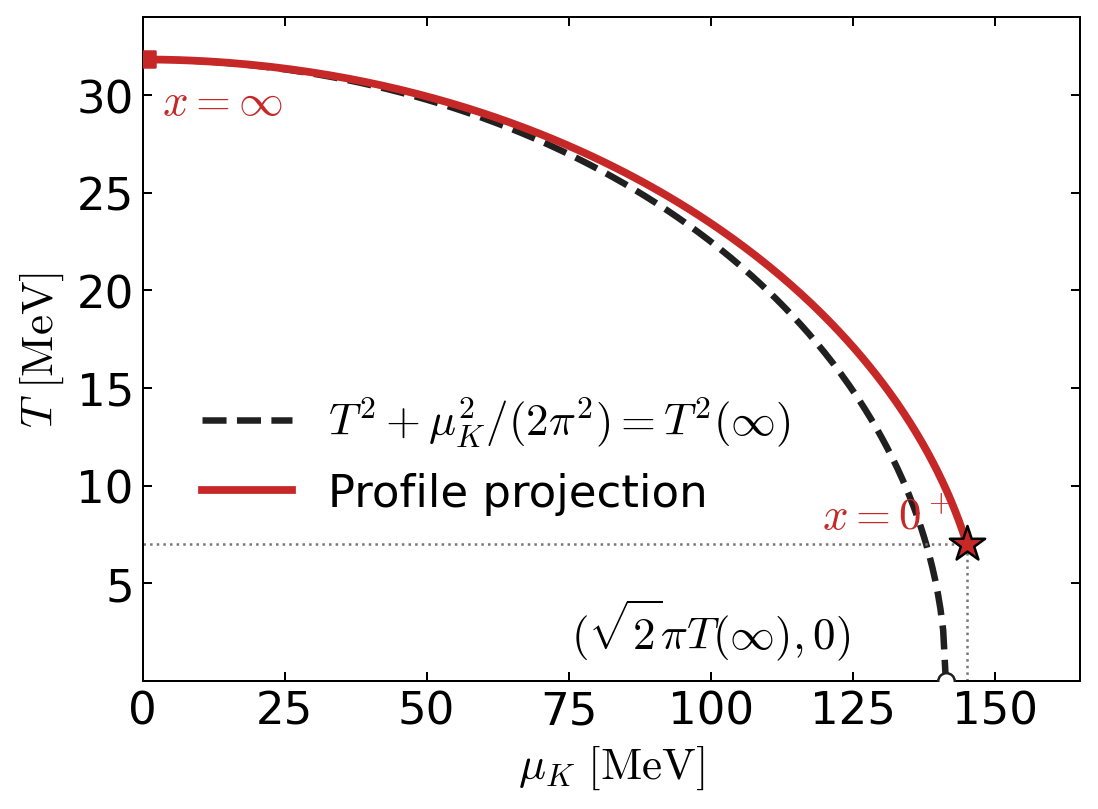

Profile: local_analysis_results/All_Plots_new/energy_conserving_nK_TN10_TQstar3_nBN3n0_B180.csv
T_Q = 31.823486 MeV
muK endpoint = 141.388023 MeV
Interface: muK = 145.109635 MeV, T = 6.990575 MeV
Maximum |T_profile - T_isobar| = 9.782804 MeV
Saved: Latex_writting/Hydrodynamical combustion/Plots/T_muK_constant_pressure.pdf


In [5]:
# Tunable plotting parameters
PROFILE_CSV = "local_analysis_results/All_Plots_new/energy_conserving_nK_TN10_TQstar3_nBN3n0_B180.csv"
OUTPUT_PDF = "Latex_writting/Hydrodynamical combustion/Plots/T_muK_constant_pressure.pdf"
FIGURE_SIZE = (6.2, 4.6)
FIGURE_DPI = 180
EXPORT_DPI = 300
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
LEGEND_FONT_SIZE = 18
ANNOTATION_FONT_SIZE = 18
LINE_WIDTH = 2.6
PROFILE_LINE_WIDTH = 3.1
PROJECTION_LINE_WIDTH = 1.0
MARKER_SIZE = 80
ENDPOINT_MARKER_SCALE = 0.55
MARKER_ZORDER = 5
QSTAR_MARKER_STYLE = "*"
QSTAR_MARKER_SIZE = 220
QSTAR_EDGE_COLOR = "black"
QSTAR_EDGE_LINE_WIDTH = 1.0
DOWNSTREAM_MARKER_STYLE = "s"
ENDPOINT_FACE_COLOR = "white"
PROFILE_COLOR = "#c62828"
ELLIPSE_COLOR = "#202020"
PROJECTION_COLOR = "#777777"
ELLIPSE_LINE_STYLE = "--"
PROJECTION_LINE_STYLE = ":"
GRID_POINTS = 300
X_LIMITS = (0.0, 165.0)
Y_LIMITS = (0.0, 34.0)
X_TICKS = (0.0, 25.0, 50.0, 75.0, 100.0, 125.0, 150.0)
Y_TICKS = (0.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0)
TICK_DIRECTION = "in"
SHOW_TOP_TICKS = True
SHOW_RIGHT_TICKS = True
LEGEND_LOCATION = "center left"
LEGEND_FRAME = False
LEGEND_BBOX_TO_ANCHOR = (0.02, 0.34)
ELLIPSE_LABEL = r"$T^2+\mu_K^2/(2\pi^2)=T^2(\infty)$"
PROFILE_LABEL = "Profile projection"
DOWNSTREAM_ENDPOINT_LABEL = r"$x = \infty$"
INTERFACE_ENDPOINT_LABEL = r"$x = 0^+$"
X_AXIS_LABEL = r"$\mu_K\ \mathrm{[MeV]}$"
Y_AXIS_LABEL = r"$T\ \mathrm{[MeV]}$"
QBAR_LABEL_OFFSET = (6, -22)
QSTAR_LABEL_OFFSET = (-58, 6)
ENDPOINT_LABEL_OFFSET = (-150, 13)
SHOW_GRID = False
GRID_ALPHA = 0.15
SHOW_QSTAR_PROJECTIONS = True
SHOW_ENDPOINT_LABEL = True
SAVE_TRANSPARENT = False
BOUNDING_BOX = "tight"

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

profile_path = Path(PROFILE_CSV)
output_pdf_path = Path(OUTPUT_PDF)
output_pdf_path.parent.mkdir(parents=True, exist_ok=True)

data = pd.read_csv(profile_path)
profile = data[data["D"].notna()].copy()
profile = profile.sort_values("muK")

# The first row after sorting is the equilibrated downstream endpoint.
qbar = profile.iloc[0]
qstar = profile.iloc[-1]
T_Q = float(qbar["T"])

# The quadratic constant-pressure relation is T^2 + muK^2/(2 pi^2) = T_Q^2.
muK_endpoint = np.sqrt(2.0) * np.pi * T_Q
muK_isobar = np.linspace(0.0, muK_endpoint, GRID_POINTS)
T_isobar = np.sqrt(np.maximum(T_Q**2 - muK_isobar**2 / (2.0 * np.pi**2), 0.0))

# Evaluate the same approximation on the numerical profile for a diagnostic.
profile_muK = profile["muK"].to_numpy(dtype=float)
T_profile_isobar = np.sqrt(
    np.maximum(T_Q**2 - profile_muK**2 / (2.0 * np.pi**2), 0.0)
)
max_temperature_difference = np.max(np.abs(profile["T"].to_numpy() - T_profile_isobar))

mpl.rcParams.update(
    {
        "mathtext.fontset": "cm",
        "mathtext.rm": "serif",
        "mathtext.it": "serif:italic",
        "mathtext.bf": "serif:bold",
    }
)

fig, ax = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI)
ax.plot(
    muK_isobar,
    T_isobar,
    color=ELLIPSE_COLOR,
    linewidth=LINE_WIDTH,
    linestyle=ELLIPSE_LINE_STYLE,
    label=ELLIPSE_LABEL,
)
ax.plot(
    profile["muK"],
    profile["T"],
    color=PROFILE_COLOR,
    linewidth=PROFILE_LINE_WIDTH,
    label=PROFILE_LABEL,
)

ax.scatter(
    qbar["muK"], qbar["T"],
    s=ENDPOINT_MARKER_SCALE * MARKER_SIZE,
    marker=DOWNSTREAM_MARKER_STYLE,
    color=PROFILE_COLOR,
    zorder=MARKER_ZORDER,
)
ax.scatter(
    qstar["muK"], qstar["T"],
    s=QSTAR_MARKER_SIZE,
    marker=QSTAR_MARKER_STYLE,
    color=PROFILE_COLOR,
    edgecolor=QSTAR_EDGE_COLOR,
    linewidths=QSTAR_EDGE_LINE_WIDTH,
    zorder=MARKER_ZORDER,
)
ax.scatter(
    muK_endpoint, 0.0,
    s=ENDPOINT_MARKER_SCALE * MARKER_SIZE,
    facecolor=ENDPOINT_FACE_COLOR,
    edgecolor=ELLIPSE_COLOR,
    zorder=MARKER_ZORDER,
)

ax.annotate(
    DOWNSTREAM_ENDPOINT_LABEL,
    (qbar["muK"], qbar["T"]),
    xytext=QBAR_LABEL_OFFSET,
    textcoords="offset points",
    fontsize=ANNOTATION_FONT_SIZE,
    color=PROFILE_COLOR,
)
ax.annotate(
    INTERFACE_ENDPOINT_LABEL,
    (qstar["muK"], qstar["T"]),
    xytext=QSTAR_LABEL_OFFSET,
    textcoords="offset points",
    fontsize=ANNOTATION_FONT_SIZE,
    color=PROFILE_COLOR,
)
if SHOW_ENDPOINT_LABEL:
    ax.annotate(
        r"$(\sqrt{2}\pi T(\infty),0)$",
        (muK_endpoint, 0.0),
        xytext=ENDPOINT_LABEL_OFFSET,
        textcoords="offset points",
        fontsize=ANNOTATION_FONT_SIZE,
    )

if SHOW_QSTAR_PROJECTIONS:
    ax.plot(
        [qstar["muK"], qstar["muK"]],
        [0.0, qstar["T"]],
        color=PROJECTION_COLOR,
        linewidth=PROJECTION_LINE_WIDTH,
        linestyle=PROJECTION_LINE_STYLE,
    )
    ax.plot(
        [0.0, qstar["muK"]],
        [qstar["T"], qstar["T"]],
        color=PROJECTION_COLOR,
        linewidth=PROJECTION_LINE_WIDTH,
        linestyle=PROJECTION_LINE_STYLE,
    )

ax.set_xlabel(X_AXIS_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
ax.set_ylabel(Y_AXIS_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
ax.set_xlim(*X_LIMITS)
ax.set_ylim(*Y_LIMITS)
ax.set_xticks(X_TICKS)
ax.set_yticks(Y_TICKS)
ax.set_yticklabels(["" if np.isclose(y, 0.0) else f"{y:g}" for y in Y_TICKS])
ax.tick_params(
    which="both",
    direction=TICK_DIRECTION,
    top=SHOW_TOP_TICKS,
    right=SHOW_RIGHT_TICKS,
    labelsize=TICK_LABEL_FONT_SIZE,
)
if SHOW_GRID:
    ax.grid(alpha=GRID_ALPHA)
ax.legend(
    frameon=LEGEND_FRAME,
    fontsize=LEGEND_FONT_SIZE,
    loc=LEGEND_LOCATION,
    bbox_to_anchor=LEGEND_BBOX_TO_ANCHOR,
)

fig.tight_layout()
fig.savefig(
    output_pdf_path,
    dpi=EXPORT_DPI,
    bbox_inches=BOUNDING_BOX,
    transparent=SAVE_TRANSPARENT,
)
plt.show()

print(f"Profile: {profile_path}")
print(f"T_Q = {T_Q:.6f} MeV")
print(f"muK endpoint = {muK_endpoint:.6f} MeV")
print(f"Interface: muK = {qstar['muK']:.6f} MeV, T = {qstar['T']:.6f} MeV")
print(f"Maximum |T_profile - T_isobar| = {max_temperature_difference:.6f} MeV")
print(f"Saved: {output_pdf_path}")


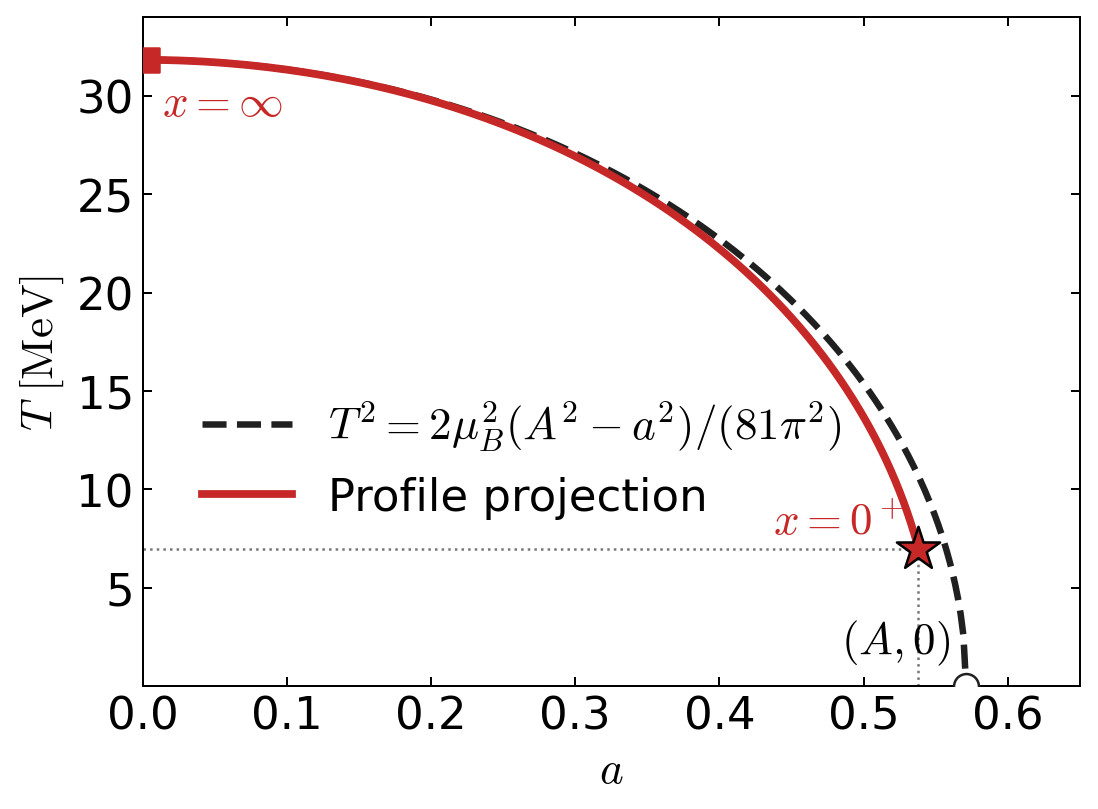

Profile: local_analysis_results/All_Plots_new/energy_conserving_nK_TN10_TQstar3_nBN3n0_B180.csv
T_Q = 31.823486 MeV
muB_Q = 1114.168999 MeV
A endpoint = 0.571050
Interface: a = 0.538000, T = 6.990575 MeV
Maximum |T_profile - T_isobar| = 3.678686 MeV
Saved: Latex_writting/Hydrodynamical combustion/Plots/T_a_constant_pressure.pdf


In [6]:
# Tunable plotting parameters
PROFILE_CSV = "local_analysis_results/All_Plots_new/energy_conserving_nK_TN10_TQstar3_nBN3n0_B180.csv"
OUTPUT_PDF = "Latex_writting/Hydrodynamical combustion/Plots/T_a_constant_pressure.pdf"
FIGURE_SIZE = (6.2, 4.6)
FIGURE_DPI = 180
EXPORT_DPI = 300
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
LEGEND_FONT_SIZE = 18
ANNOTATION_FONT_SIZE = 18
LINE_WIDTH = 2.6
PROFILE_LINE_WIDTH = 3.1
PROJECTION_LINE_WIDTH = 1.0
MARKER_SIZE = 180
ENDPOINT_MARKER_SCALE = 0.55
MARKER_ZORDER = 5
QSTAR_MARKER_STYLE = "*"
QSTAR_MARKER_SIZE = 330
QSTAR_EDGE_COLOR = "black"
QSTAR_EDGE_LINE_WIDTH = 1.0
DOWNSTREAM_MARKER_STYLE = "s"
ENDPOINT_FACE_COLOR = "white"
PROFILE_COLOR = "#c62828"
ELLIPSE_COLOR = "#202020"
PROJECTION_COLOR = "#777777"
ELLIPSE_LINE_STYLE = "--"
PROJECTION_LINE_STYLE = ":"
GRID_POINTS = 300
X_LIMITS = (0.0, 0.65)
Y_LIMITS = (0.0, 34.0)
X_TICKS = (0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6)
Y_TICKS = (0.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0)
TICK_DIRECTION = "in"
SHOW_TOP_TICKS = True
SHOW_RIGHT_TICKS = True
LEGEND_LOCATION = "center left"
LEGEND_FRAME = False
LEGEND_BBOX_TO_ANCHOR = (0.02, 0.34)
ELLIPSE_LABEL = r"$T^2 = 2\mu_B^2(A^2 - a^2)/(81\pi^2)$"
PROFILE_LABEL = "Profile projection"
DOWNSTREAM_ENDPOINT_LABEL = r"$x = \infty$"
INTERFACE_ENDPOINT_LABEL = r"$x = 0^+$"
X_AXIS_LABEL = r"$a$"
Y_AXIS_LABEL = r"$T\ \mathrm{[MeV]}$"
QBAR_LABEL_OFFSET = (6, -22)
QSTAR_LABEL_OFFSET = (-58, 6)
ENDPOINT_LABEL_OFFSET = (-50, 13)
SHOW_GRID = False
GRID_ALPHA = 0.15
SHOW_QSTAR_PROJECTIONS = True
SHOW_ENDPOINT_LABEL = True
SAVE_TRANSPARENT = False
BOUNDING_BOX = "tight"

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

profile_path = Path(PROFILE_CSV)
output_pdf_path = Path(OUTPUT_PDF)
output_pdf_path.parent.mkdir(parents=True, exist_ok=True)

data = pd.read_csv(profile_path)
profile = data[data["D"].notna()].copy()
profile = profile.sort_values("a")

# The first row after sorting is the equilibrated downstream endpoint.
qbar = profile.iloc[0]
qstar = profile.iloc[-1]
T_Q = float(qbar["T"])
muB_Q = float(qbar["muB"])

# A is the zero-temperature endpoint of the isobar in the (a,T) plane:
# A = 9*pi*T_Q/(sqrt(2)*muB_Q), so that T(a)^2/T_Q^2 + (a/A)^2 = 1.
A_endpoint = (9.0 * np.pi / np.sqrt(2.0)) * (T_Q / muB_Q)
a_isobar = np.linspace(0.0, A_endpoint, GRID_POINTS)
T_isobar = T_Q * np.sqrt(np.maximum(1.0 - (a_isobar / A_endpoint) ** 2, 0.0))

# Evaluate the same approximation on the numerical profile for a diagnostic.
profile_a = profile["a"].to_numpy(dtype=float)
T_profile_isobar = T_Q * np.sqrt(
    np.maximum(1.0 - (profile_a / A_endpoint) ** 2, 0.0)
)
max_temperature_difference = np.max(np.abs(profile["T"].to_numpy() - T_profile_isobar))

mpl.rcParams.update(
    {
        "mathtext.fontset": "cm",
        "mathtext.rm": "serif",
        "mathtext.it": "serif:italic",
        "mathtext.bf": "serif:bold",
    }
)

fig, ax = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI)
ax.plot(
    a_isobar,
    T_isobar,
    color=ELLIPSE_COLOR,
    linewidth=LINE_WIDTH,
    linestyle=ELLIPSE_LINE_STYLE,
    label=ELLIPSE_LABEL,
)
ax.plot(
    profile["a"],
    profile["T"],
    color=PROFILE_COLOR,
    linewidth=PROFILE_LINE_WIDTH,
    label=PROFILE_LABEL,
)

ax.scatter(
    qbar["a"], qbar["T"],
    s=ENDPOINT_MARKER_SCALE * MARKER_SIZE,
    marker=DOWNSTREAM_MARKER_STYLE,
    color=PROFILE_COLOR,
    zorder=MARKER_ZORDER,
)
ax.scatter(
    qstar["a"], qstar["T"],
    s=QSTAR_MARKER_SIZE,
    marker=QSTAR_MARKER_STYLE,
    color=PROFILE_COLOR,
    edgecolor=QSTAR_EDGE_COLOR,
    linewidths=QSTAR_EDGE_LINE_WIDTH,
    zorder=MARKER_ZORDER,
)
ax.scatter(
    A_endpoint, 0.0,
    s=ENDPOINT_MARKER_SCALE * MARKER_SIZE,
    facecolor=ENDPOINT_FACE_COLOR,
    edgecolor=ELLIPSE_COLOR,
    zorder=MARKER_ZORDER,
)

ax.annotate(
    DOWNSTREAM_ENDPOINT_LABEL,
    (qbar["a"], qbar["T"]),
    xytext=QBAR_LABEL_OFFSET,
    textcoords="offset points",
    fontsize=ANNOTATION_FONT_SIZE,
    color=PROFILE_COLOR,
)
ax.annotate(
    INTERFACE_ENDPOINT_LABEL,
    (qstar["a"], qstar["T"]),
    xytext=QSTAR_LABEL_OFFSET,
    textcoords="offset points",
    fontsize=ANNOTATION_FONT_SIZE,
    color=PROFILE_COLOR,
)
if SHOW_ENDPOINT_LABEL:
    ax.annotate(
        r"$(A,0)$",
        (A_endpoint, 0.0),
        xytext=ENDPOINT_LABEL_OFFSET,
        textcoords="offset points",
        fontsize=ANNOTATION_FONT_SIZE,
    )

if SHOW_QSTAR_PROJECTIONS:
    ax.plot(
        [qstar["a"], qstar["a"]],
        [0.0, qstar["T"]],
        color=PROJECTION_COLOR,
        linewidth=PROJECTION_LINE_WIDTH,
        linestyle=PROJECTION_LINE_STYLE,
    )
    ax.plot(
        [0.0, qstar["a"]],
        [qstar["T"], qstar["T"]],
        color=PROJECTION_COLOR,
        linewidth=PROJECTION_LINE_WIDTH,
        linestyle=PROJECTION_LINE_STYLE,
    )

ax.set_xlabel(X_AXIS_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
ax.set_ylabel(Y_AXIS_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
ax.set_xlim(*X_LIMITS)
ax.set_ylim(*Y_LIMITS)
ax.set_xticks(X_TICKS)
ax.set_yticks(Y_TICKS)
ax.set_yticklabels(["" if np.isclose(y, 0.0) else f"{y:g}" for y in Y_TICKS])
ax.tick_params(
    which="both",
    direction=TICK_DIRECTION,
    top=SHOW_TOP_TICKS,
    right=SHOW_RIGHT_TICKS,
    labelsize=TICK_LABEL_FONT_SIZE,
)
if SHOW_GRID:
    ax.grid(alpha=GRID_ALPHA)
ax.legend(
    frameon=LEGEND_FRAME,
    fontsize=LEGEND_FONT_SIZE,
    loc=LEGEND_LOCATION,
    bbox_to_anchor=LEGEND_BBOX_TO_ANCHOR,
)

fig.tight_layout()
fig.savefig(
    output_pdf_path,
    dpi=EXPORT_DPI,
    bbox_inches=BOUNDING_BOX,
    transparent=SAVE_TRANSPARENT,
)
plt.show()

print(f"Profile: {profile_path}")
print(f"T_Q = {T_Q:.6f} MeV")
print(f"muB_Q = {muB_Q:.6f} MeV")
print(f"A endpoint = {A_endpoint:.6f}")
print(f"Interface: a = {qstar['a']:.6f}, T = {qstar['T']:.6f} MeV")
print(f"Maximum |T_profile - T_isobar| = {max_temperature_difference:.6f} MeV")
print(f"Saved: {output_pdf_path}")


For massless quarks at fixed $\mu_B=3\mu_q$, the pressure difference from the equilibrated endpoint is, to quadratic order in $\mu_K$ and $T$, proportional to

$$
\frac{3\mu_q^2}{4\pi^2}\mu_K^2+\frac{3\mu_q^2}{2}(T^2-T_Q^2).
$$

Constant pressure therefore gives $T^2=T_Q^2-\mu_K^2/(2\pi^2)$. Using $a\simeq3\mu_K/(2\mu_q)$ and defining the cold endpoint by $T(A)=0$ gives the plotted quarter ellipse.

# Latest linear T local-$n_K$ cluster contour

This final panel visualizes the latest local-$n_K$ numerical cluster output from `new_paper_calculations/26-06-23/`. The contours show the maximum upstream velocity $u_N^{\max}$ in $\mathrm{m\,s^{-1}}$ over the metastability--temperature plane. The shaded region lies above the LTE endpoint boundary where the local-$n_K$ construction would require $a(0^+)^{\mathrm{LTE}}>1$.


,raw mesh cells,raw finite velocity cells,raw velocity min/max [m/s],contour levels used [m/s]
0,600,597,12.5 / 2.02e+03,"50, 100, 200, 500, 1000"


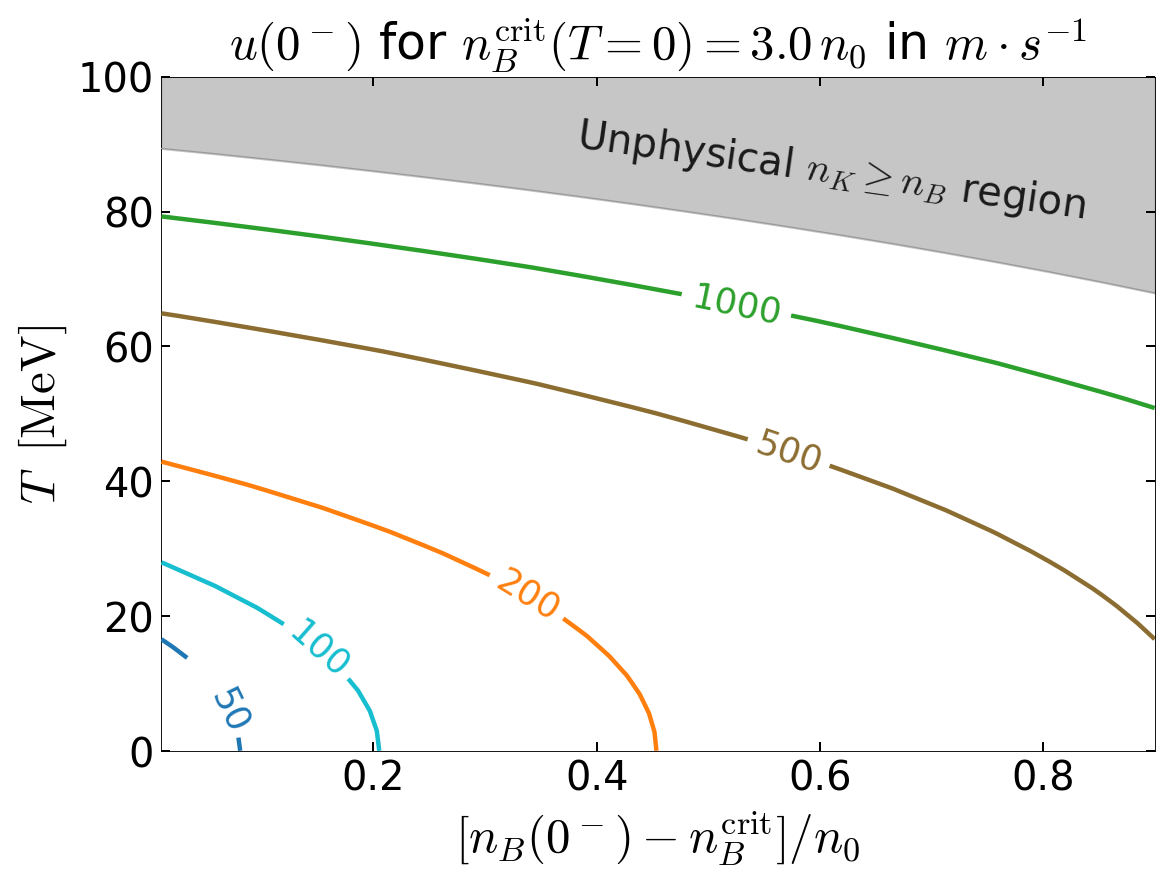

In [7]:
# Tunable plotting parameters
# Editable plot controls
DATA_PATH = "new_paper_calculations/26-06-23/hydro-numerical-uNmax-adaptive-contour__numerical_uNmax_nK_v2.npy"
OUTPUT_DIR = "Latex_writting/Hydrodynamical combustion/Plots/"
PDF_FILENAME = "uNmax-numerical-contour.pdf"
FIGSIZE = (7.2, 5.4)
FIGURE_DPI = 160
X_LIMITS = (0.01, 0.9)
Y_LIMITS = (0.0, 100.0)
CONTOUR_LEVELS_M_S = [50, 100, 200, 500, 1000]
CONTOUR_COLORS = ["#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c"]
CONTOUR_CMAP = None
NUMERICAL_CONTOUR_LINESTYLE = "-"
NUMERICAL_CONTOUR_LINE_WIDTH = 2.0
BOUNDARY_LINEWIDTH = 0.5
SHADE_COLOR = "0.72"
SHADE_ALPHA = 0.8
BACKGROUND_COLOR = "white"
BOUNDARY_COLOR = "0.60"
TITLE_FONTSIZE = 22
AXIS_LABEL_FONT_SIZE = 22
TICK_FONTSIZE = 18
CONTOUR_LABEL_FONTSIZE = 16
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 5
TICK_LENGTH = 4.0
TICK_WIDTH = 0.9
SPINE_LINEWIDTH = 0.4
CONTOUR_ZORDER = 3
BOUNDARY_ZORDER = 4
SHADE_ZORDER = 0
SHADE_LABEL_X = 0.55          # x position of gray-region label (data coords)
SHADE_LABEL_Y = 93.0          # y position of gray-region label (data coords)
SHADE_LABEL_FONTSIZE = 18
SHADE_LABEL_COLOR = "0.10"

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

payload = np.load(DATA_PATH, allow_pickle=True).item()
OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

M = np.asarray(payload["metastability_grid"], dtype=float)
T = np.asarray(payload["temperature_grid"], dtype=float)
V = np.asarray(payload["velocity_grid_m_s"], dtype=float)
boundary_m = np.asarray(payload["boundary_metastability_values"], dtype=float)
boundary_T = np.asarray(payload["boundary_temperature_values"], dtype=float)
ncrit_over_n0 = float(payload["nB_crit"]) / float(payload["n0"])

mesh_finite = np.isfinite(M) & np.isfinite(T)
velocity_finite = mesh_finite & np.isfinite(V) & (V > 0.0)
if not np.any(velocity_finite):
    raise ValueError(f"No finite positive velocities found in {DATA_PATH}")

finite_boundary = np.isfinite(boundary_m) & np.isfinite(boundary_T)
boundary_order = np.argsort(boundary_m[finite_boundary])
boundary_m = boundary_m[finite_boundary][boundary_order]
boundary_T = boundary_T[finite_boundary][boundary_order]

available_levels = [
    float(level)
    for level in CONTOUR_LEVELS_M_S
    if np.nanmin(V[velocity_finite]) <= float(level) <= np.nanmax(V[velocity_finite])
]
if not available_levels:
    raise ValueError(
        "None of CONTOUR_LEVELS_M_S fall inside the raw velocity range "
        f"[{np.nanmin(V[velocity_finite]):.3g}, {np.nanmax(V[velocity_finite]):.3g}] m/s"
    )
level_to_color = dict(zip([float(level) for level in CONTOUR_LEVELS_M_S], CONTOUR_COLORS))
contour_colors = [level_to_color[level] for level in available_levels]

raw_velocity = np.ma.masked_where(~velocity_finite, V)
diagnostic = pd.DataFrame([
    {
        "raw mesh cells": int(np.count_nonzero(mesh_finite)),
        "raw finite velocity cells": int(np.count_nonzero(velocity_finite)),
        "raw velocity min/max [m/s]": f"{np.nanmin(V[velocity_finite]):.3g} / {np.nanmax(V[velocity_finite]):.3g}",
        "contour levels used [m/s]": ", ".join(f"{level:.0f}" for level in available_levels),
    }
])
display(diagnostic)

fig, ax = plt.subplots(
    figsize=FIGSIZE,
    dpi=FIGURE_DPI,
    constrained_layout=True,
    facecolor=BACKGROUND_COLOR,
)
ax.set_facecolor(BACKGROUND_COLOR)
ax.fill_between(
    boundary_m,
    boundary_T,
    Y_LIMITS[1],
    color=SHADE_COLOR,
    alpha=SHADE_ALPHA,
    zorder=SHADE_ZORDER,
)
ax.plot(
    boundary_m,
    boundary_T,
    color=BOUNDARY_COLOR,
    lw=BOUNDARY_LINEWIDTH,
    zorder=BOUNDARY_ZORDER,
)

contour = ax.contour(
    M,
    T,
    raw_velocity,
    levels=available_levels,
    colors=contour_colors,
    cmap=None if contour_colors is not None else CONTOUR_CMAP,
    linewidths=NUMERICAL_CONTOUR_LINE_WIDTH,
    linestyles=NUMERICAL_CONTOUR_LINESTYLE,
    zorder=CONTOUR_ZORDER,
)
ax.clabel(
    contour,
    contour.levels,
    inline=CONTOUR_LABEL_INLINE,
    inline_spacing=CONTOUR_LABEL_INLINE_SPACING,
    fontsize=CONTOUR_LABEL_FONTSIZE,
    fmt=lambda value: f"{value:.0f}",
)

ax.set_xlim(*X_LIMITS)
ax.set_ylim(*Y_LIMITS)
ax.set_xlabel(r"$[n_B(0^-)-n_B^{\rm crit}]/n_0$", fontsize=AXIS_LABEL_FONT_SIZE)
ax.set_ylabel(r"$T\;\; \rm{[MeV]}$", fontsize=AXIS_LABEL_FONT_SIZE)
ax.set_title(
    rf"$u(0^-)$ for $n_B^{{\rm crit}}(T=0)={ncrit_over_n0:.1f}\,n_0$ in $m\cdot s^{{-1}}$",
    fontsize=TITLE_FONTSIZE,
    pad=8,
)
ax.tick_params(
    direction="in",
    top=True,
    right=True,
    length=TICK_LENGTH,
    width=TICK_WIDTH,
    labelsize=TICK_FONTSIZE,
)
for spine in ax.spines.values():
    spine.set_linewidth(SPINE_LINEWIDTH)
ax.text(
    0.61,
    86,
    r"Unphysical $n_K \geq n_B$ region",
    fontsize=SHADE_LABEL_FONTSIZE,
    ha="center",
    va="center",
    color=SHADE_LABEL_COLOR,
    zorder=SHADE_ZORDER + 1,
    rotation=-8
)

pdf_path = OUTPUT_DIR / PDF_FILENAME
fig.savefig(pdf_path, facecolor=BACKGROUND_COLOR)
plt.show()
#print(f"Saved {pdf_path}")


# Raw local-$n_K$ cluster velocity grid

The contour plot above interpolates a partially masked adaptive cluster grid. This diagnostic shows the raw stored $u_N^{\max}$ matrix directly with `imshow`: the horizontal axis is metastability, the vertical axis is the adaptive temperature-row index, and gray cells are missing or failed solver points. Because the adaptive temperature mesh depends on metastability, this raw view intentionally uses row index rather than pretending that every column shares the same temperature coordinate.


# Analytic LTE velocity contour

This panel uses the latest analytic LTE cluster payload from `new_paper_calculations/26-06-23/`. The plotting style matches the local-$n_K$ numerical $u_N^{\max}$ contour above, but the color contours now show the analytic LTE velocity from `hydro-analytic-LTE-adaptive-contour__analytic_LTE_v1.npy`.


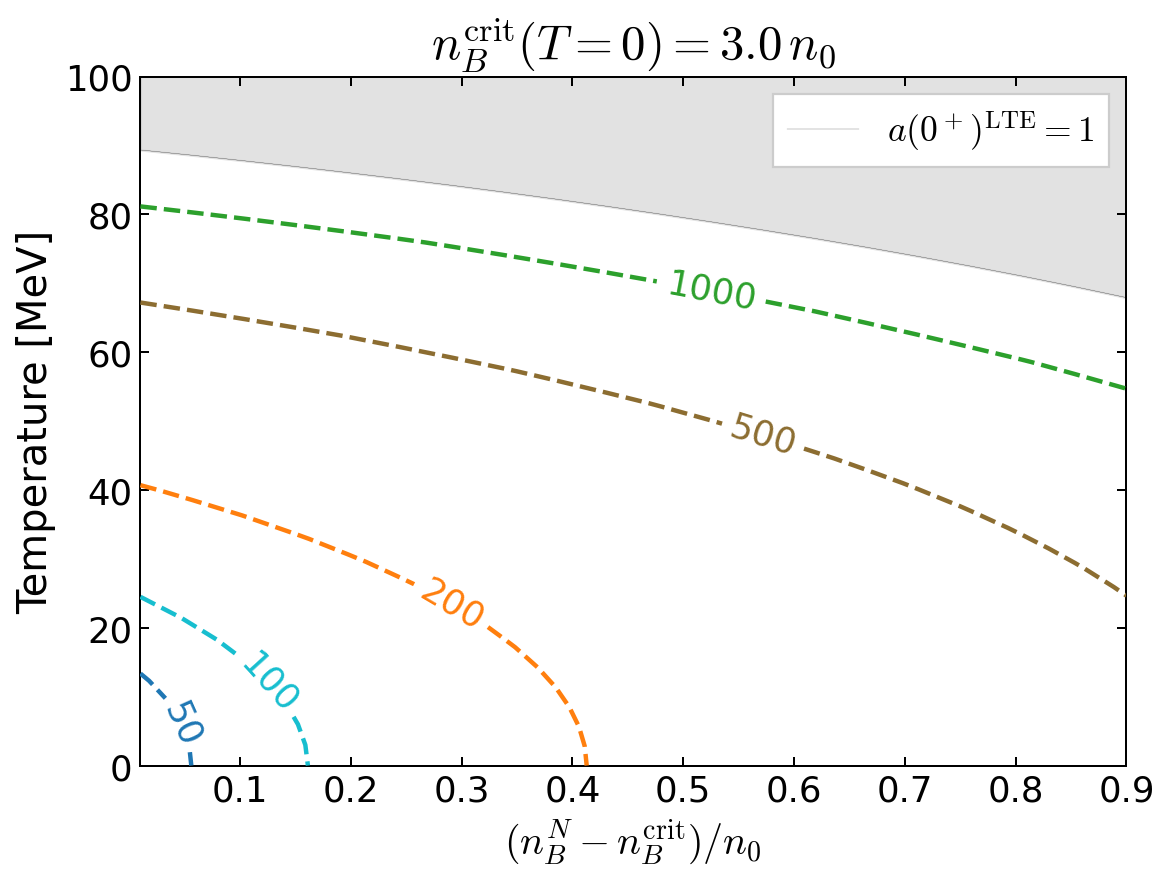

Saved local_analysis_results/All_Plots_new/23Jun-analytic-LTE-velocity-contour.pdf


In [8]:
# Tunable plotting parameters
# Editable plot controls
DATA_PATH = "new_paper_calculations/26-06-23/hydro-analytic-LTE-adaptive-contour__analytic_LTE_v1.npy"
UNMAX_BOUNDARY_DATA_PATH = "new_paper_calculations/26-06-23/hydro-numerical-uNmax-adaptive-contour__numerical_uNmax_nK_v2.npy"
OUTPUT_DIR = "local_analysis_results/All_Plots_new"
PDF_FILENAME = "23Jun-analytic-LTE-velocity-contour.pdf"
FIGSIZE = (7.2, 5.4)
FIGURE_DPI = 160
X_LIMITS = (0.01, 0.9)
Y_LIMITS = (0.0, 100.0)
CONTOUR_LEVELS_M_S = [50, 100, 200, 500, 1000]
CONTOUR_COLORS = ["#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c"]
CONTOUR_CMAP = None
ANALYTIC_LINE_STYLE = "--"
ANALYTIC_CONTOUR_LINE_WIDTH = 2.0
BOUNDARY_LINEWIDTH = 0.1
SHADE_COLOR = "0.72"
SHADE_ALPHA = 0.40
BACKGROUND_COLOR = "white"
BOUNDARY_COLOR = "black"
TITLE_FONTSIZE = 22
AXIS_LABEL_FONT_SIZE = 18
TICK_FONTSIZE = 16
CONTOUR_LABEL_FONTSIZE = 16
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 5
LEGEND_FONTSIZE = 16
TICK_LENGTH = 4.0
TICK_WIDTH = 0.9
SPINE_LINEWIDTH = 0.9
CONTOUR_ZORDER = 3
BOUNDARY_ZORDER = 4
SHADE_ZORDER = 0
LEGEND_LOCATION = "upper right"
LEGEND_FRAME = True
LEGEND_FANCYBOX = False
LEGEND_FRAME_ALPHA = 1.0

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

payload = np.load(DATA_PATH, allow_pickle=True).item()
unmax_boundary_payload = np.load(UNMAX_BOUNDARY_DATA_PATH, allow_pickle=True).item()
OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

M = np.asarray(payload["metastability_grid"], dtype=float)
T = np.asarray(payload["temperature_grid"], dtype=float)
V = np.asarray(payload["velocity_grid_m_s"], dtype=float)
boundary_m = np.asarray(unmax_boundary_payload["boundary_metastability_values"], dtype=float)
boundary_T = np.asarray(unmax_boundary_payload["boundary_temperature_values"], dtype=float)
ncrit_over_n0 = float(payload["nB_crit"]) / float(payload["n0"])

mesh_finite = np.isfinite(M) & np.isfinite(T)
finite = mesh_finite & np.isfinite(V) & (V > 0.0)
if not np.any(finite):
    raise ValueError(f"No finite positive velocities found in {DATA_PATH}")

finite_boundary = np.isfinite(boundary_m) & np.isfinite(boundary_T)
boundary_order = np.argsort(boundary_m[finite_boundary])
boundary_m = boundary_m[finite_boundary][boundary_order]
boundary_T = boundary_T[finite_boundary][boundary_order]

available_levels = [
    float(level)
    for level in CONTOUR_LEVELS_M_S
    if np.nanmin(V[finite]) <= float(level) <= np.nanmax(V[finite])
]
if not available_levels:
    raise ValueError(
        "None of CONTOUR_LEVELS_M_S fall inside the finite velocity range "
        f"[{np.nanmin(V[finite]):.3g}, {np.nanmax(V[finite]):.3g}] m/s"
    )
level_to_color = dict(zip([float(level) for level in CONTOUR_LEVELS_M_S], CONTOUR_COLORS))
contour_colors = [level_to_color[level] for level in available_levels]

fig, ax = plt.subplots(
    figsize=FIGSIZE,
    dpi=FIGURE_DPI,
    constrained_layout=True,
    facecolor=BACKGROUND_COLOR,
)
ax.set_facecolor(BACKGROUND_COLOR)
ax.fill_between(
    boundary_m,
    boundary_T,
    Y_LIMITS[1],
    color=SHADE_COLOR,
    alpha=SHADE_ALPHA,
    zorder=SHADE_ZORDER,
)
ax.plot(
    boundary_m,
    boundary_T,
    color=BOUNDARY_COLOR,
    lw=BOUNDARY_LINEWIDTH,
    label=r"$a(0^+)^{\rm LTE}=1$",
    zorder=BOUNDARY_ZORDER,
)

contour = ax.contour(
    M,
    T,
    np.ma.masked_where(~finite, V),
    levels=available_levels,
    colors=contour_colors,
    cmap=None if contour_colors is not None else CONTOUR_CMAP,
    linewidths=ANALYTIC_CONTOUR_LINE_WIDTH,
    linestyles=ANALYTIC_LINE_STYLE,
    zorder=CONTOUR_ZORDER,
)
ax.clabel(
    contour,
    contour.levels,
    inline=CONTOUR_LABEL_INLINE,
    inline_spacing=CONTOUR_LABEL_INLINE_SPACING,
    fontsize=CONTOUR_LABEL_FONTSIZE,
    fmt=lambda value: f"{value:.0f}",
)

ax.set_xlim(*X_LIMITS)
ax.set_ylim(*Y_LIMITS)
ax.set_xlabel(r"$(n_B^N-n_B^{\rm crit})/n_0$", fontsize=AXIS_LABEL_FONT_SIZE)
ax.set_ylabel("Temperature [MeV]", fontsize=AXIS_LABEL_FONT_SIZE)
ax.set_title(
    rf"$n_B^{{\rm crit}}(T=0)={ncrit_over_n0:.1f}\,n_0$",
    fontsize=TITLE_FONTSIZE,
    pad=8,
)
ax.tick_params(
    direction="in",
    top=True,
    right=True,
    length=TICK_LENGTH,
    width=TICK_WIDTH,
    labelsize=TICK_FONTSIZE,
)
for spine in ax.spines.values():
    spine.set_linewidth(SPINE_LINEWIDTH)
ax.legend(
    loc=LEGEND_LOCATION,
    fontsize=LEGEND_FONTSIZE,
    frameon=LEGEND_FRAME,
    fancybox=LEGEND_FANCYBOX,
    framealpha=LEGEND_FRAME_ALPHA,
)

pdf_path = OUTPUT_DIR / PDF_FILENAME
fig.savefig(pdf_path, facecolor=BACKGROUND_COLOR)
plt.show()
print(f"Saved {pdf_path}")


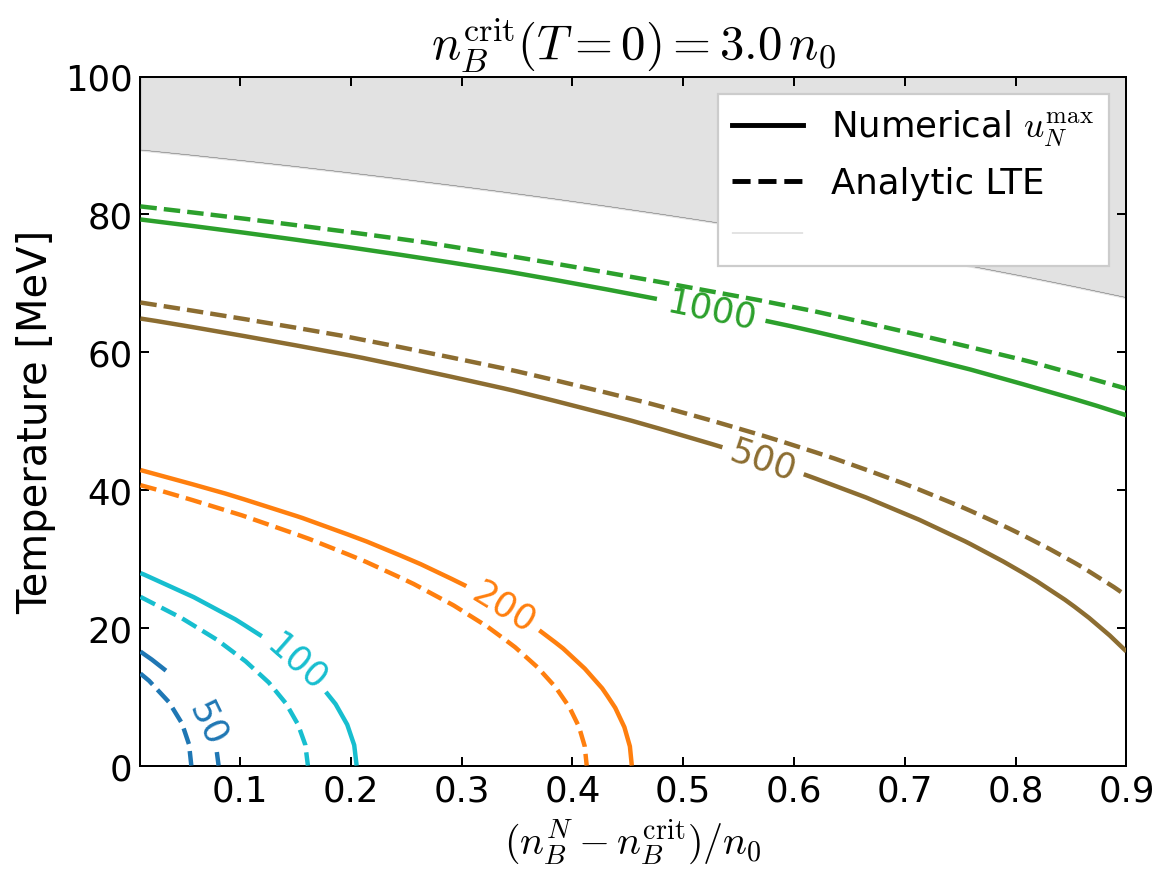

Saved local_analysis_results/All_Plots_new/23Jun-numerical-vs-analytic-LTE-velocity-contours.pdf


In [9]:
# Tunable plotting parameters
# Editable plot controls
NUMERICAL_DATA_PATH = "new_paper_calculations/26-06-23/hydro-numerical-uNmax-adaptive-contour__numerical_uNmax_nK_v2.npy"
ANALYTIC_DATA_PATH = "new_paper_calculations/26-06-23/hydro-analytic-LTE-adaptive-contour__analytic_LTE_v1.npy"
OUTPUT_DIR = "local_analysis_results/All_Plots_new"
PDF_FILENAME = "23Jun-numerical-vs-analytic-LTE-velocity-contours.pdf"
FIGSIZE = (7.2, 5.4)
FIGURE_DPI = 160
X_LIMITS = (0.01, 0.9)
Y_LIMITS = (0.0, 100.0)
CONTOUR_LEVELS_M_S = [50, 100, 200, 500, 1000]
CONTOUR_COLORS = ["#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c"]
CONTOUR_CMAP = None
ANALYTIC_LINE_STYLE = "--"
NUMERICAL_CONTOUR_LINESTYLE = "-"
ANALYTIC_CONTOUR_LINE_WIDTH = 2.0
NUMERICAL_CONTOUR_LINE_WIDTH = 2.0
BOUNDARY_LINEWIDTH = 0.1
SHADE_COLOR = "0.72"
SHADE_ALPHA = 0.40
BACKGROUND_COLOR = "white"
BOUNDARY_COLOR = "black"
TITLE_FONTSIZE = 22
AXIS_LABEL_FONT_SIZE = 18
TICK_FONTSIZE = 16
CONTOUR_LABEL_FONTSIZE = 16
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 5
LEGEND_FONTSIZE = 16
TICK_LENGTH = 4.0
TICK_WIDTH = 0.9
SPINE_LINEWIDTH = 0.9
ANALYTIC_CONTOUR_ZORDER = 3
NUMERICAL_CONTOUR_ZORDER = 4
BOUNDARY_ZORDER = 5
SHADE_ZORDER = 0
LEGEND_LOCATION = "upper right"
LEGEND_FRAME = True
LEGEND_FANCYBOX = False
LEGEND_FRAME_ALPHA = 1.0
METHOD_LEGEND_LINEWIDTH = 2.2

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
numerical_payload = np.load(NUMERICAL_DATA_PATH, allow_pickle=True).item()
analytic_payload = np.load(ANALYTIC_DATA_PATH, allow_pickle=True).item()

def extract_raw_payload_grid(payload):
    M = np.asarray(payload["metastability_grid"], dtype=float)
    T = np.asarray(payload["temperature_grid"], dtype=float)
    V = np.asarray(payload["velocity_grid_m_s"], dtype=float)
    finite = np.isfinite(M) & np.isfinite(T) & np.isfinite(V) & (V > 0.0)
    if not np.any(finite):
        raise ValueError("No finite positive velocities found in payload")
    return M, T, V, finite

M_num, T_num, V_num, finite_num = extract_raw_payload_grid(numerical_payload)
M_ana, T_ana, V_ana, finite_ana = extract_raw_payload_grid(analytic_payload)

boundary_m = np.asarray(numerical_payload["boundary_metastability_values"], dtype=float)
boundary_T = np.asarray(numerical_payload["boundary_temperature_values"], dtype=float)
finite_boundary = np.isfinite(boundary_m) & np.isfinite(boundary_T)
boundary_order = np.argsort(boundary_m[finite_boundary])
boundary_m = boundary_m[finite_boundary][boundary_order]
boundary_T = boundary_T[finite_boundary][boundary_order]
ncrit_over_n0 = float(numerical_payload["nB_crit"]) / float(numerical_payload["n0"])

numerical_available_levels = [
    float(level)
    for level in CONTOUR_LEVELS_M_S
    if np.nanmin(V_num[finite_num]) <= float(level) <= np.nanmax(V_num[finite_num])
]
analytic_available_levels = [
    float(level)
    for level in CONTOUR_LEVELS_M_S
    if np.nanmin(V_ana[finite_ana]) <= float(level) <= np.nanmax(V_ana[finite_ana])
]
available_levels = [
    float(level)
    for level in CONTOUR_LEVELS_M_S
    if float(level) in numerical_available_levels and float(level) in analytic_available_levels
]
if not available_levels:
    raise ValueError("No shared contour levels are available in both raw payloads")
level_to_color = dict(zip([float(level) for level in CONTOUR_LEVELS_M_S], CONTOUR_COLORS))
contour_colors = [level_to_color[level] for level in available_levels]

fig, ax = plt.subplots(
    figsize=FIGSIZE,
    dpi=FIGURE_DPI,
    constrained_layout=True,
    facecolor=BACKGROUND_COLOR,
)
ax.set_facecolor(BACKGROUND_COLOR)
ax.fill_between(
    boundary_m,
    boundary_T,
    Y_LIMITS[1],
    color=SHADE_COLOR,
    alpha=SHADE_ALPHA,
    zorder=SHADE_ZORDER,
)
ax.plot(
    boundary_m,
    boundary_T,
    color=BOUNDARY_COLOR,
    lw=BOUNDARY_LINEWIDTH,
    zorder=BOUNDARY_ZORDER,
)

analytic_contour = ax.contour(
    M_ana,
    T_ana,
    np.ma.masked_where(~finite_ana, V_ana),
    levels=available_levels,
    colors=contour_colors,
    cmap=None if contour_colors is not None else CONTOUR_CMAP,
    linewidths=ANALYTIC_CONTOUR_LINE_WIDTH,
    linestyles=ANALYTIC_LINE_STYLE,
    zorder=ANALYTIC_CONTOUR_ZORDER,
)
numerical_contour = ax.contour(
    M_num,
    T_num,
    np.ma.masked_where(~finite_num, V_num),
    levels=available_levels,
    colors=contour_colors,
    cmap=None if contour_colors is not None else CONTOUR_CMAP,
    linewidths=NUMERICAL_CONTOUR_LINE_WIDTH,
    linestyles=NUMERICAL_CONTOUR_LINESTYLE,
    zorder=NUMERICAL_CONTOUR_ZORDER,
)
ax.clabel(
    numerical_contour,
    numerical_contour.levels,
    inline=CONTOUR_LABEL_INLINE,
    inline_spacing=CONTOUR_LABEL_INLINE_SPACING,
    fontsize=CONTOUR_LABEL_FONTSIZE,
    fmt=lambda value: f"{value:.0f}",
)

method_handles = [
    Line2D(
        [0],
        [0],
        color="black",
        lw=METHOD_LEGEND_LINEWIDTH,
        linestyle=NUMERICAL_CONTOUR_LINESTYLE,
        label=r"Numerical $u_N^{\max}$",
    ),
    Line2D(
        [0],
        [0],
        color="black",
        lw=METHOD_LEGEND_LINEWIDTH,
        linestyle=ANALYTIC_LINE_STYLE,
        label="Analytic LTE",
    ),
    Line2D(
        [0],
        [0],
        color=BOUNDARY_COLOR,
        lw=BOUNDARY_LINEWIDTH,
        linestyle="-",
        #label=r"$a(0^+)^{\rm LTE}=1$",
    ),
]

ax.set_xlim(*X_LIMITS)
ax.set_ylim(*Y_LIMITS)
ax.set_xlabel(r"$(n_B^N-n_B^{\rm crit})/n_0$", fontsize=AXIS_LABEL_FONT_SIZE)
ax.set_ylabel("Temperature [MeV]", fontsize=AXIS_LABEL_FONT_SIZE)
ax.set_title(
    rf"$n_B^{{\rm crit}}(T=0)={ncrit_over_n0:.1f}\,n_0$",
    fontsize=TITLE_FONTSIZE,
    pad=8,
)
ax.tick_params(
    direction="in",
    top=True,
    right=True,
    length=TICK_LENGTH,
    width=TICK_WIDTH,
    labelsize=TICK_FONTSIZE,
)
for spine in ax.spines.values():
    spine.set_linewidth(SPINE_LINEWIDTH)
ax.legend(
    handles=method_handles,
    loc=LEGEND_LOCATION,
    fontsize=LEGEND_FONTSIZE,
    frameon=LEGEND_FRAME,
    fancybox=LEGEND_FANCYBOX,
    framealpha=LEGEND_FRAME_ALPHA,
)

pdf_path = OUTPUT_DIR / PDF_FILENAME
fig.savefig(pdf_path, facecolor=BACKGROUND_COLOR)
plt.show()
print(f"Saved {pdf_path}")


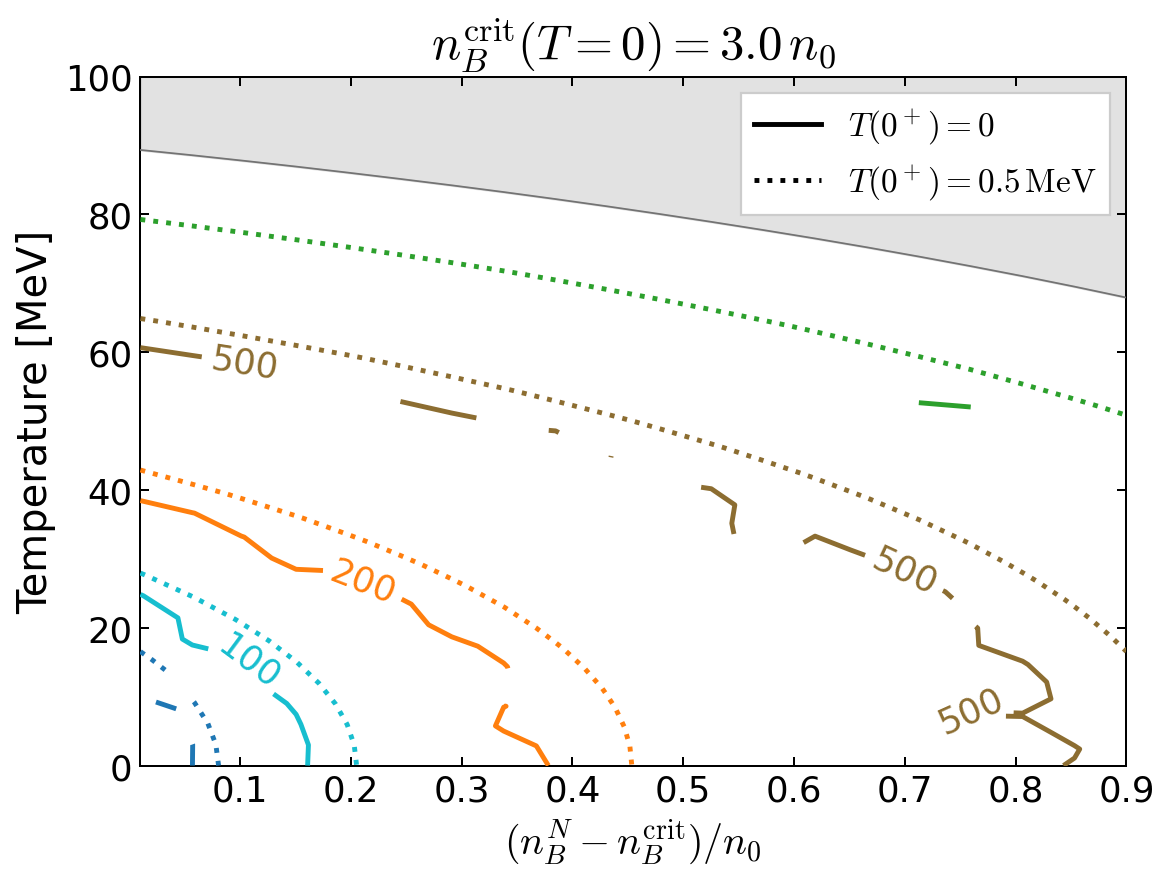

TQstar=0 finite cells: 384/600; TQstar=0.5 MeV finite cells: 597/600
Saved local_analysis_results/All_Plots_new/25Jun-uNmax-TQstar-zero-vs-half-MeV-contours.pdf


In [10]:
# Tunable plotting parameters
# 25Jun numerical uNmax TQstar comparison
TQSTAR_ZERO_DATA_PATH = "new_paper_calculations/26-06-25/hydro-numerical-uNmax-adaptive-contour__numerical_uNmax_nK_v2.npy"
TQSTAR_HALF_MEV_DATA_PATH = "new_paper_calculations/26-06-23/hydro-numerical-uNmax-adaptive-contour__numerical_uNmax_nK_v2.npy"
OUTPUT_DIRECTORY = "local_analysis_results/All_Plots_new"
OUTPUT_PDF_FILENAME = "25Jun-uNmax-TQstar-zero-vs-half-MeV-contours.pdf"
EXPECTED_TQSTAR_ZERO_MEV = 0.0
EXPECTED_TQSTAR_HALF_MEV = 0.5
FIGURE_SIZE = (7.2, 5.4)
FIGURE_DPI = 160
CONSTRAINED_LAYOUT = True
X_LIMITS = (0.01, 0.9)
Y_LIMITS = (0.0, 100.0)
CONTOUR_LEVELS_M_S = [50, 100, 200, 500, 1000]
CONTOUR_COLORS = ["#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c"]
TQSTAR_ZERO_LINE_STYLE = "-"
TQSTAR_HALF_MEV_LINE_STYLE = ":"
TQSTAR_ZERO_LINE_WIDTH = 2.2
TQSTAR_HALF_MEV_LINE_WIDTH = 2.2
TQSTAR_ZERO_ZORDER = 4
TQSTAR_HALF_MEV_ZORDER = 3
BOUNDARY_LINE_COLOR = "0.45"
BOUNDARY_LINE_STYLE = "-"
BOUNDARY_LINE_WIDTH = 0.8
BOUNDARY_ZORDER = 5
SHADE_COLOR = "0.72"
SHADE_ALPHA = 0.40
SHADE_ZORDER = 0
BACKGROUND_COLOR = "white"
TITLE_FONT_SIZE = 22
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 16
CONTOUR_LABEL_FONT_SIZE = 16
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 5
LEGEND_FONT_SIZE = 15
LEGEND_LOCATION = "upper right"
LEGEND_FRAME = True
LEGEND_FANCYBOX = False
LEGEND_FRAME_ALPHA = 1.0
LEGEND_LINE_COLOR = "black"
LEGEND_LINE_WIDTH = 2.2
TICK_DIRECTION = "in"
SHOW_TOP_TICKS = True
SHOW_RIGHT_TICKS = True
TICK_LENGTH = 4.0
TICK_WIDTH = 0.9
SPINE_LINE_WIDTH = 0.9
TITLE_PAD = 8
SAVE_BBOX_INCHES = "tight"

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

output_directory = Path(OUTPUT_DIRECTORY)
output_directory.mkdir(parents=True, exist_ok=True)
zero_payload = np.load(TQSTAR_ZERO_DATA_PATH, allow_pickle=True).item()
half_payload = np.load(TQSTAR_HALF_MEV_DATA_PATH, allow_pickle=True).item()

zero_TQstar = float(zero_payload["TQstar_target_MeV"])
half_TQstar = float(half_payload["TQstar_target_MeV"])
if not np.isclose(zero_TQstar, EXPECTED_TQSTAR_ZERO_MEV):
    raise ValueError(f"Expected TQstar={EXPECTED_TQSTAR_ZERO_MEV} MeV in {TQSTAR_ZERO_DATA_PATH}, found {zero_TQstar}")
if not np.isclose(half_TQstar, EXPECTED_TQSTAR_HALF_MEV):
    raise ValueError(f"Expected TQstar={EXPECTED_TQSTAR_HALF_MEV} MeV in {TQSTAR_HALF_MEV_DATA_PATH}, found {half_TQstar}")

def extract_native_grid(payload, data_path):
    metastability_grid = np.asarray(payload["metastability_grid"], dtype=float)
    temperature_grid = np.asarray(payload["temperature_grid"], dtype=float)
    velocity_grid = np.asarray(payload["velocity_grid_m_s"], dtype=float)
    finite = (
        np.isfinite(metastability_grid)
        & np.isfinite(temperature_grid)
        & np.isfinite(velocity_grid)
        & (velocity_grid > 0.0)
    )
    if not np.any(finite):
        raise ValueError(f"No finite positive velocities found in {data_path}")
    return metastability_grid, temperature_grid, velocity_grid, finite

M_zero, T_zero, V_zero, finite_zero = extract_native_grid(zero_payload, TQSTAR_ZERO_DATA_PATH)
M_half, T_half, V_half, finite_half = extract_native_grid(half_payload, TQSTAR_HALF_MEV_DATA_PATH)

available_levels = [
    float(level)
    for level in CONTOUR_LEVELS_M_S
    if np.nanmin(V_zero[finite_zero]) <= float(level) <= np.nanmax(V_zero[finite_zero])
    and np.nanmin(V_half[finite_half]) <= float(level) <= np.nanmax(V_half[finite_half])
]
if not available_levels:
    raise ValueError("No requested contour levels are available in both numerical payloads")
level_to_color = dict(zip([float(level) for level in CONTOUR_LEVELS_M_S], CONTOUR_COLORS))
contour_colors = [level_to_color[level] for level in available_levels]

boundary_m = np.asarray(zero_payload["boundary_metastability_values"], dtype=float)
boundary_T = np.asarray(zero_payload["boundary_temperature_values"], dtype=float)
finite_boundary = np.isfinite(boundary_m) & np.isfinite(boundary_T)
boundary_order = np.argsort(boundary_m[finite_boundary])
boundary_m = boundary_m[finite_boundary][boundary_order]
boundary_T = boundary_T[finite_boundary][boundary_order]
ncrit_over_n0 = float(zero_payload["nB_crit"]) / float(zero_payload["n0"])

fig, ax = plt.subplots(
    figsize=FIGURE_SIZE,
    dpi=FIGURE_DPI,
    constrained_layout=CONSTRAINED_LAYOUT,
    facecolor=BACKGROUND_COLOR,
)
ax.set_facecolor(BACKGROUND_COLOR)
ax.fill_between(
    boundary_m,
    boundary_T,
    Y_LIMITS[1],
    color=SHADE_COLOR,
    alpha=SHADE_ALPHA,
    zorder=SHADE_ZORDER,
)
ax.plot(
    boundary_m,
    boundary_T,
    color=BOUNDARY_LINE_COLOR,
    linestyle=BOUNDARY_LINE_STYLE,
    linewidth=BOUNDARY_LINE_WIDTH,
    zorder=BOUNDARY_ZORDER,
)

half_contour = ax.contour(
    M_half,
    T_half,
    np.ma.masked_where(~finite_half, V_half),
    levels=available_levels,
    colors=contour_colors,
    linewidths=TQSTAR_HALF_MEV_LINE_WIDTH,
    linestyles=TQSTAR_HALF_MEV_LINE_STYLE,
    zorder=TQSTAR_HALF_MEV_ZORDER,
)
zero_contour = ax.contour(
    M_zero,
    T_zero,
    np.ma.masked_where(~finite_zero, V_zero),
    levels=available_levels,
    colors=contour_colors,
    linewidths=TQSTAR_ZERO_LINE_WIDTH,
    linestyles=TQSTAR_ZERO_LINE_STYLE,
    zorder=TQSTAR_ZERO_ZORDER,
)
ax.clabel(
    zero_contour,
    zero_contour.levels,
    inline=CONTOUR_LABEL_INLINE,
    inline_spacing=CONTOUR_LABEL_INLINE_SPACING,
    fontsize=CONTOUR_LABEL_FONT_SIZE,
    fmt=lambda value: f"{value:.0f}",
)

comparison_handles = [
    Line2D(
        [0],
        [0],
        color=LEGEND_LINE_COLOR,
        linewidth=LEGEND_LINE_WIDTH,
        linestyle=TQSTAR_ZERO_LINE_STYLE,
        label=r"$T(0^+)=0$",
    ),
    Line2D(
        [0],
        [0],
        color=LEGEND_LINE_COLOR,
        linewidth=LEGEND_LINE_WIDTH,
        linestyle=TQSTAR_HALF_MEV_LINE_STYLE,
        label=r"$T(0^+)=0.5\,\mathrm{MeV}$",
    ),
]

ax.set_xlim(*X_LIMITS)
ax.set_ylim(*Y_LIMITS)
ax.set_xlabel(r"$(n_B^N-n_B^{\rm crit})/n_0$", fontsize=AXIS_LABEL_FONT_SIZE)
ax.set_ylabel("Temperature [MeV]", fontsize=AXIS_LABEL_FONT_SIZE)
ax.set_title(
    rf"$n_B^{{\rm crit}}(T=0)={ncrit_over_n0:.1f}\,n_0$",
    fontsize=TITLE_FONT_SIZE,
    pad=TITLE_PAD,
)
ax.tick_params(
    direction=TICK_DIRECTION,
    top=SHOW_TOP_TICKS,
    right=SHOW_RIGHT_TICKS,
    length=TICK_LENGTH,
    width=TICK_WIDTH,
    labelsize=TICK_LABEL_FONT_SIZE,
)
for spine in ax.spines.values():
    spine.set_linewidth(SPINE_LINE_WIDTH)
ax.legend(
    handles=comparison_handles,
    loc=LEGEND_LOCATION,
    fontsize=LEGEND_FONT_SIZE,
    frameon=LEGEND_FRAME,
    fancybox=LEGEND_FANCYBOX,
    framealpha=LEGEND_FRAME_ALPHA,
)

pdf_path = output_directory / OUTPUT_PDF_FILENAME
fig.savefig(pdf_path, facecolor=BACKGROUND_COLOR, bbox_inches=SAVE_BBOX_INCHES)
plt.show()
print(
    f"TQstar=0 finite cells: {int(np.count_nonzero(finite_zero))}/{V_zero.size}; "
    f"TQstar=0.5 MeV finite cells: {int(np.count_nonzero(finite_half))}/{V_half.size}"
)
print(f"Saved {pdf_path}")


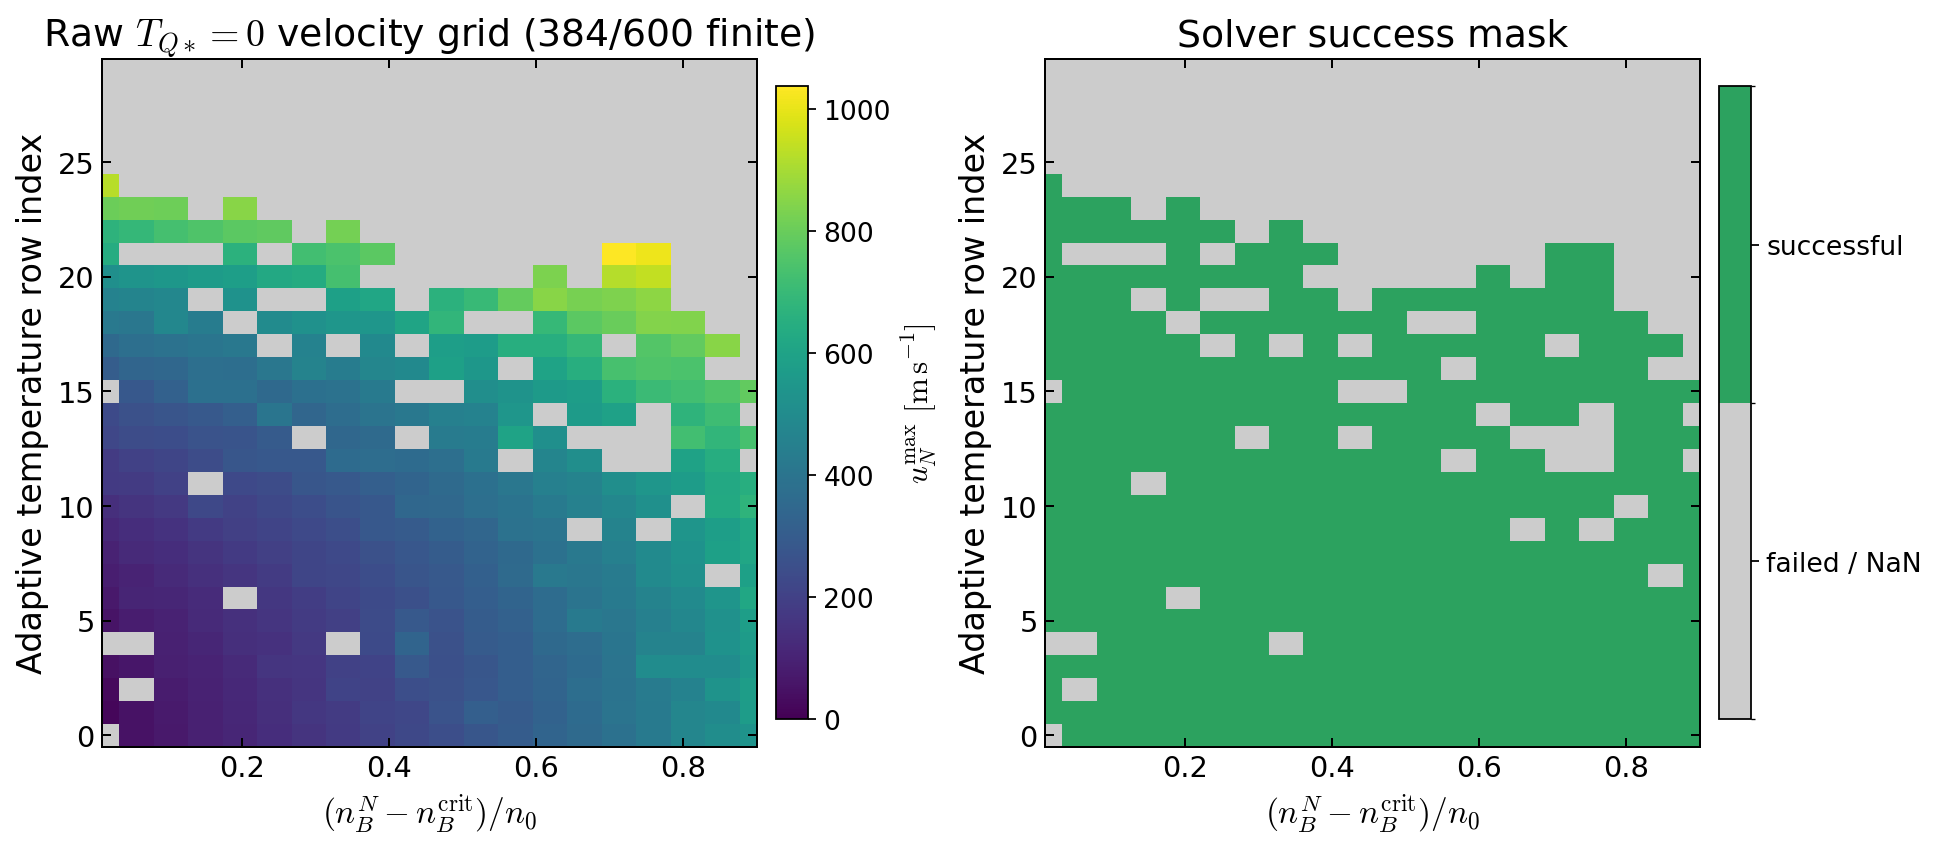

Successful cells: 384/600; failed or missing cells: 216
Successful cells by adaptive row: [19, 20, 19, 20, 17, 20, 19, 19, 20, 18, 19, 19, 16, 15, 17, 17, 17, 15, 15, 13, 11, 7, 7, 4, 1, 0, 0, 0, 0, 0]
Saved local_analysis_results/All_Plots_new/25Jun-uNmax-raw-grid-imshow-diagnostic.pdf


In [11]:
# Tunable plotting parameters
# 25Jun raw uNmax imshow diagnostic
DATA_PATH = "new_paper_calculations/26-06-25/hydro-numerical-uNmax-adaptive-contour__numerical_uNmax_nK_v2.npy"
OUTPUT_DIRECTORY = "local_analysis_results/All_Plots_new"
OUTPUT_PDF_FILENAME = "25Jun-uNmax-raw-grid-imshow-diagnostic.pdf"
FIGURE_SIZE = (12.0, 5.2)
FIGURE_DPI = 160
CONSTRAINED_LAYOUT = True
X_LIMITS = (0.01, 0.9)
ROW_TICK_INTERVAL = 5
IMAGE_ASPECT = "auto"
IMAGE_ORIGIN = "lower"
IMAGE_INTERPOLATION = "nearest"
VELOCITY_COLORMAP = "viridis"
VELOCITY_MIN_M_S = 0.0
VELOCITY_MAX_M_S = None
MISSING_CELL_COLOR = "0.80"
FAILURE_CELL_COLOR = "0.80"
SUCCESS_CELL_COLOR = "#2ca25f"
BACKGROUND_COLOR = "white"
TITLE_FONT_SIZE = 17
AXIS_LABEL_FONT_SIZE = 15
TICK_LABEL_FONT_SIZE = 13
COLORBAR_LABEL_FONT_SIZE = 14
COLORBAR_TICK_FONT_SIZE = 12
COLORBAR_SHRINK = 0.92
COLORBAR_PAD = 0.03
TICK_DIRECTION = "in"
SHOW_TOP_TICKS = True
SHOW_RIGHT_TICKS = True
TICK_LENGTH = 4.0
TICK_WIDTH = 0.9
SPINE_LINE_WIDTH = 0.9
SAVE_BBOX_INCHES = "tight"

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import BoundaryNorm, ListedColormap

output_directory = Path(OUTPUT_DIRECTORY)
output_directory.mkdir(parents=True, exist_ok=True)
payload = np.load(DATA_PATH, allow_pickle=True).item()

metastability_grid = np.asarray(payload["metastability_grid"], dtype=float)
temperature_grid = np.asarray(payload["temperature_grid"], dtype=float)
velocity_grid = np.asarray(payload["velocity_grid_m_s"], dtype=float)
if metastability_grid.shape != temperature_grid.shape or velocity_grid.shape != temperature_grid.shape:
    raise ValueError("Stored metastability, temperature, and velocity grids must have identical shapes")

success_mask = np.isfinite(velocity_grid) & (velocity_grid > 0.0)
if not np.any(success_mask):
    raise ValueError(f"No finite positive velocities found in {DATA_PATH}")
masked_velocity = np.ma.masked_where(~success_mask, velocity_grid)
metastability_axis = np.asarray(metastability_grid[0, :], dtype=float)
if metastability_axis.size < 2 or not np.all(np.isfinite(metastability_axis)):
    raise ValueError("At least two finite metastability columns are required for imshow")
metastability_spacing = float(np.nanmedian(np.diff(metastability_axis)))
image_extent = (
    float(metastability_axis[0] - 0.5 * metastability_spacing),
    float(metastability_axis[-1] + 0.5 * metastability_spacing),
    -0.5,
    float(velocity_grid.shape[0]) - 0.5,
)
velocity_max = float(np.nanmax(velocity_grid[success_mask])) if VELOCITY_MAX_M_S is None else float(VELOCITY_MAX_M_S)

velocity_cmap = plt.get_cmap(VELOCITY_COLORMAP).copy()
velocity_cmap.set_bad(MISSING_CELL_COLOR)
status_cmap = ListedColormap([FAILURE_CELL_COLOR, SUCCESS_CELL_COLOR])
status_norm = BoundaryNorm([-0.5, 0.5, 1.5], status_cmap.N)

fig, axes = plt.subplots(
    1,
    2,
    figsize=FIGURE_SIZE,
    dpi=FIGURE_DPI,
    constrained_layout=CONSTRAINED_LAYOUT,
    facecolor=BACKGROUND_COLOR,
)
for ax in axes:
    ax.set_facecolor(BACKGROUND_COLOR)

velocity_image = axes[0].imshow(
    masked_velocity,
    origin=IMAGE_ORIGIN,
    aspect=IMAGE_ASPECT,
    interpolation=IMAGE_INTERPOLATION,
    extent=image_extent,
    cmap=velocity_cmap,
    vmin=VELOCITY_MIN_M_S,
    vmax=velocity_max,
)
velocity_colorbar = fig.colorbar(
    velocity_image,
    ax=axes[0],
    shrink=COLORBAR_SHRINK,
    pad=COLORBAR_PAD,
)
velocity_colorbar.set_label(r"$u_N^{\max}\ [\mathrm{m\,s^{-1}}]$", fontsize=COLORBAR_LABEL_FONT_SIZE)
velocity_colorbar.ax.tick_params(labelsize=COLORBAR_TICK_FONT_SIZE)

status_image = axes[1].imshow(
    success_mask.astype(int),
    origin=IMAGE_ORIGIN,
    aspect=IMAGE_ASPECT,
    interpolation=IMAGE_INTERPOLATION,
    extent=image_extent,
    cmap=status_cmap,
    norm=status_norm,
)
status_colorbar = fig.colorbar(
    status_image,
    ax=axes[1],
    ticks=[0, 1],
    shrink=COLORBAR_SHRINK,
    pad=COLORBAR_PAD,
)
status_colorbar.ax.set_yticklabels(["failed / NaN", "successful"])
status_colorbar.ax.tick_params(labelsize=COLORBAR_TICK_FONT_SIZE)

finite_count = int(np.count_nonzero(success_mask))
total_count = int(success_mask.size)
axes[0].set_title(
    rf"Raw $T_{{Q*}}=0$ velocity grid ({finite_count}/{total_count} finite)",
    fontsize=TITLE_FONT_SIZE,
)
axes[1].set_title("Solver success mask", fontsize=TITLE_FONT_SIZE)
row_ticks = np.arange(0, velocity_grid.shape[0], ROW_TICK_INTERVAL)
for ax in axes:
    ax.set_xlim(*X_LIMITS)
    ax.set_ylim(image_extent[2], image_extent[3])
    ax.set_yticks(row_ticks)
    ax.set_xlabel(r"$(n_B^N-n_B^{\rm crit})/n_0$", fontsize=AXIS_LABEL_FONT_SIZE)
    ax.set_ylabel("Adaptive temperature row index", fontsize=AXIS_LABEL_FONT_SIZE)
    ax.tick_params(
        direction=TICK_DIRECTION,
        top=SHOW_TOP_TICKS,
        right=SHOW_RIGHT_TICKS,
        length=TICK_LENGTH,
        width=TICK_WIDTH,
        labelsize=TICK_LABEL_FONT_SIZE,
    )
    for spine in ax.spines.values():
        spine.set_linewidth(SPINE_LINE_WIDTH)

pdf_path = output_directory / OUTPUT_PDF_FILENAME
fig.savefig(pdf_path, facecolor=BACKGROUND_COLOR, bbox_inches=SAVE_BBOX_INCHES)
plt.show()
print(f"Successful cells: {finite_count}/{total_count}; failed or missing cells: {total_count - finite_count}")
print(f"Successful cells by adaptive row: {np.count_nonzero(success_mask, axis=1).tolist()}")
print(f"Saved {pdf_path}")


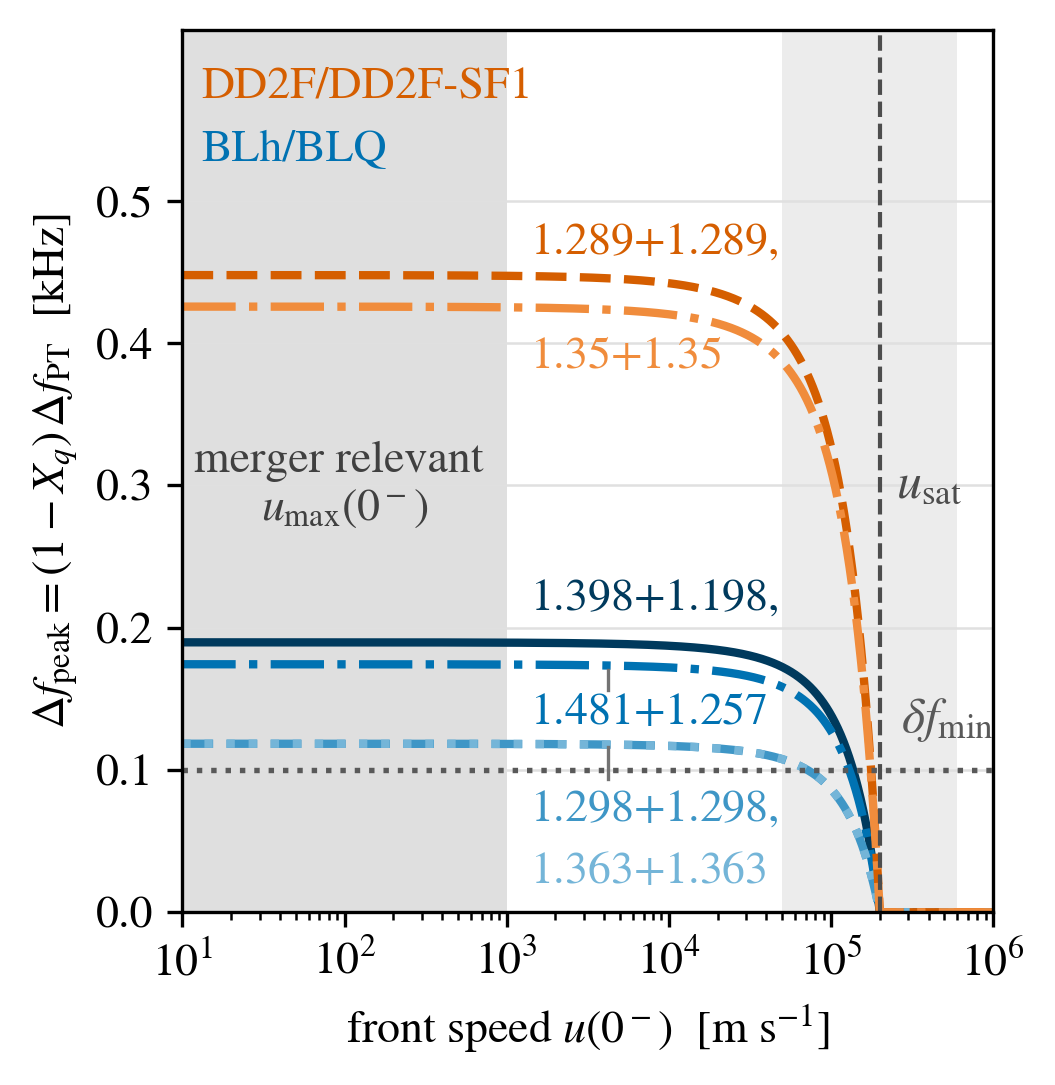

wrote Latex_writting/Hydrodynamical combustion/Plots/.pdf/.png


In [12]:
# GW-section figure: finite-rate frequency deficit for simulation-calibrated
# Delta_f_PT. Five cases (all BLh/BLQ + DD2F/DD2F-SF1 1.289+1.289) are from
# Table IV of Prakash+ arXiv:2310.06025; the DD2F/DD2F-SF1 1.35+1.35 case is
# from Bauswein+ arXiv:1809.01116. A second Bauswein+ case (q=0.8) was dropped:
# its m1,m2 split could not be verified, see comment at DD2F_CASES below.
# Uses the paper's two-lobed (taiji) geometry:
# X_q = min(1, ((R_0 + u*Delta_t_pm)/R_lobe)^3).
# Design: no boxed legend; color = EOS family, direct mass tags on plateaus,
# dotted delta_f_min guide. All text >= 10 pt for 1:1 columnwidth inclusion.
# Run from the repo root; writes the PDF used by the v2 drop-in section.
import numpy as np
import matplotlib.pyplot as plt

# Tunable plotting parameters
FIGURE_SIZE = (3.4, 3.5)
DPI = 300
FONT_FAMILY = "STIXGeneral"
MATH_FONTSET = "stix"
AXIS_LABEL_FONT_SIZE = 11
TICK_LABEL_FONT_SIZE = 11
TAG_FONT_SIZE = 11
FAMILY_FONT_SIZE = 11
ANNOTATION_FONT_SIZE = 11
LINE_WIDTH = 2.0
BLH_SHADES = ["#003A5D", "#0072B2", "#3E96C6", "#74B5D8"]   # dark -> light
DD2F_SHADES = ["#8A3D00", "#D55E00", "#F08C3C"]
BLH_ANCHOR = "#0072B2"
DD2F_ANCHOR = "#D55E00"
BAND_COLOR = "0.55"
BAND_ALPHA = 0.28
U_MAX_BAND = (1.0e1, 1.0e3)     # merger-relevant weak-limited u(0^-) range, m/s
DFMIN_KHZ = 0.10                # next-generation resolution (Clark+, Breschi+)
DFMIN_COLOR = "0.35"
DFMIN_STYLE = ":"
DFMIN_WIDTH = 1.3
VLINE_COLOR = "0.3"
VLINE_STYLE = "--"
VLINE_WIDTH = 1.0
GRID_COLOR = "0.88"
GRID_LINE_WIDTH = 0.6
X_LIMITS = (1.0e1, 1.0e6)
Y_LIMITS = (0.0, 0.62)
Y_TICKS = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
LEADER_COLOR = "0.45"
LEADER_WIDTH = 0.8
N_SPEED_SAMPLES = 2000
OUTPUT_STEM = "Latex_writting/Hydrodynamical combustion/Plots/"
OUTPUT_STEM_2 = "Latex_drop_in_integrated/v2/Plots/"

# Model parameters (paper reference values)
R0_M = 1000.0                   # pre-merger quark-core radius R_0 (fiducial)
R_LOBE_M = 3000.0               # effective lobe radius R_lobe (fiducial)
DT_PM_S = 10.0e-3               # postmerger emission window (fiducial)
# Geometry is NOT known per binary (Prakash+ and Bauswein+ quote no core radii),
# so one fiducial geometry is applied to all seven cases: X_q(u) is then common
# and Delta_f_PT only rescales each curve vertically. The band below shows how
# far u_sat would move over the plausible geometry range.
R_LOBE_RANGE_M = (2000.0, 4000.0)   # "a few km" quark cores in the simulations
DT_PM_RANGE_S = (5.0e-3, 20.0e-3)   # postmerger emission window range
GEOM_BAND_COLOR = "0.45"
GEOM_BAND_ALPHA = 0.13
TAG_X = 1.4e3            # colored-label anchor, between the two gray bands
LEADER_X_LO = 4.2e3      # leader-line start (just right of the tag text)
FAMILY_X = 1.3e1         # anchor for q=0.8 and the family names (back on the left)

# (Delta_f_PT [kHz], color, linestyle); endpoint calibrations, see docstring
BLH_CASES = [
    (0.197, BLH_SHADES[0], "-"),    # 1.398+1.198
    (0.181, BLH_SHADES[1], "-."),   # 1.481+1.257
    (0.123, BLH_SHADES[2], "--"),   # 1.298+1.298
    (0.123, BLH_SHADES[3], ":"),    # 1.363+1.363
]
DD2F_CASES = [
    (0.465, DD2F_SHADES[1], "--"),  # 1.289+1.289
    (0.442, DD2F_SHADES[2], "-."),  # 1.35+1.35
]
# A second Bauswein+ (1809.01116) case, q=0.8, was dropped: its m1,m2 split
# could not be verified (that paper reports only the ratio), and Prakash+
# Table IV -- the source for the OTHER five Delta_f_PT values above, but not
# the 1.35+1.35 case -- has no matching asymmetric DD2F/DD2F-SF1 entry to
# substitute in with clearly defined masses.

# Direct tags: (text, x, y_center, color, ha)
TAGS = [
    (r"$1.289{+}1.289,$", TAG_X, 0.470, DD2F_SHADES[1], "left"),
    (r"$1.35{+}1.35$", TAG_X, 0.390, DD2F_SHADES[2], "left"),
    (r"$1.398{+}1.198,$", TAG_X, 0.220, BLH_SHADES[0], "left"),
    (r"$1.481{+}1.257$", TAG_X, 0.140, BLH_SHADES[1], "left"),
    (r"$1.298{+}1.298,$", TAG_X, 0.072, BLH_SHADES[2], "left"),
    (r"$1.363{+}1.363$", TAG_X, 0.028, BLH_SHADES[3], "left"),
]
LEADERS = [                                      # stacked tag group -> its curves
    #((LEADER_X_LO, LEADER_X_LO), (0.452, 0.478)),  # DD2F 0.465/0.442 pair
    ((LEADER_X_LO, LEADER_X_LO), (0.156, 0.170)),  # BLh 0.197/0.181 pair
    ((LEADER_X_LO, LEADER_X_LO), (0.094, 0.116)),  # BLh 0.123 pair
]

FAMILY_LABELS = [
    ("DD2F/DD2F-SF1", FAMILY_X, 0.580, DD2F_ANCHOR),
    ("BLh/BLQ", FAMILY_X, 0.535, BLH_ANCHOR),
]

plt.rcParams.update({
    "font.family": FONT_FAMILY,
    "mathtext.fontset": MATH_FONTSET,
    "axes.labelsize": AXIS_LABEL_FONT_SIZE,
    "xtick.labelsize": TICK_LABEL_FONT_SIZE,
    "ytick.labelsize": TICK_LABEL_FONT_SIZE,
})

u = np.logspace(np.log10(X_LIMITS[0]), np.log10(X_LIMITS[1]), N_SPEED_SAMPLES)
X_q = np.minimum(1.0, ((R0_M + u * DT_PM_S) / R_LOBE_M) ** 3)
u_sat = (R_LOBE_M - R0_M) / DT_PM_S
u_sat_lo = (R_LOBE_RANGE_M[0] - R0_M) / DT_PM_RANGE_S[1]
u_sat_hi = (R_LOBE_RANGE_M[1] - R0_M) / DT_PM_RANGE_S[0]

fig, ax = plt.subplots(figsize=FIGURE_SIZE, dpi=DPI)

for df_pt, color, style in BLH_CASES + DD2F_CASES:
    ax.plot(u, (1.0 - X_q) * df_pt, style, color=color, lw=LINE_WIDTH)

ax.axvspan(*U_MAX_BAND, color=BAND_COLOR, alpha=BAND_ALPHA, lw=0)
ax.annotate("merger relevant \n$u_{\\rm max}(0^-)$",
            xy=(np.sqrt(U_MAX_BAND[0] * U_MAX_BAND[1]), 0.30),
            ha="center", va="center", fontsize=ANNOTATION_FONT_SIZE, color="0.25")

ax.axhline(DFMIN_KHZ, color=DFMIN_COLOR, ls=DFMIN_STYLE, lw=DFMIN_WIDTH)
ax.annotate(r"$\delta f_{\rm min}$", xy=(2.7e5, DFMIN_KHZ + 0.018),
            ha="left", va="bottom", fontsize=12, color=DFMIN_COLOR)

ax.axvspan(u_sat_lo, u_sat_hi, color=GEOM_BAND_COLOR, alpha=GEOM_BAND_ALPHA, lw=0)
ax.axvline(u_sat, color=VLINE_COLOR, ls=VLINE_STYLE, lw=VLINE_WIDTH)
ax.annotate(r"$u_{\rm sat}$", xy=(u_sat * 1.25, 0.30),
            ha="left", va="center", fontsize=12, color=VLINE_COLOR)

for text, x, y, color, ha in TAGS:
    ax.annotate(text, xy=(x, y), ha=ha, va="center",
                fontsize=TAG_FONT_SIZE, color=color)
for lx, ly in LEADERS:
    ax.plot(lx, ly, color=LEADER_COLOR, lw=LEADER_WIDTH)

for text, x, y, color in FAMILY_LABELS:
    ax.annotate(text, xy=(x, y), ha="left", va="center",
                fontsize=FAMILY_FONT_SIZE, color=color)

ax.set_xscale("log")
ax.set_xlim(*X_LIMITS)
ax.set_ylim(*Y_LIMITS)
ax.set_yticks(Y_TICKS)
ax.set_xlabel(r"front speed $u(0^-)$  [m s$^{-1}$]")
ax.set_ylabel(r"$\Delta f_{\rm peak}=(1-X_q)\,\Delta f_{\rm PT}$  [kHz]")
ax.grid(True, which="major", axis="y", color=GRID_COLOR, lw=GRID_LINE_WIDTH)

fig.tight_layout(pad=0.3)
fig.savefig(OUTPUT_STEM + "f_peak.pdf")
fig.savefig(OUTPUT_STEM_2 + "f_peak.pdf")
plt.show()
print(f"wrote {OUTPUT_STEM}.pdf/.png")

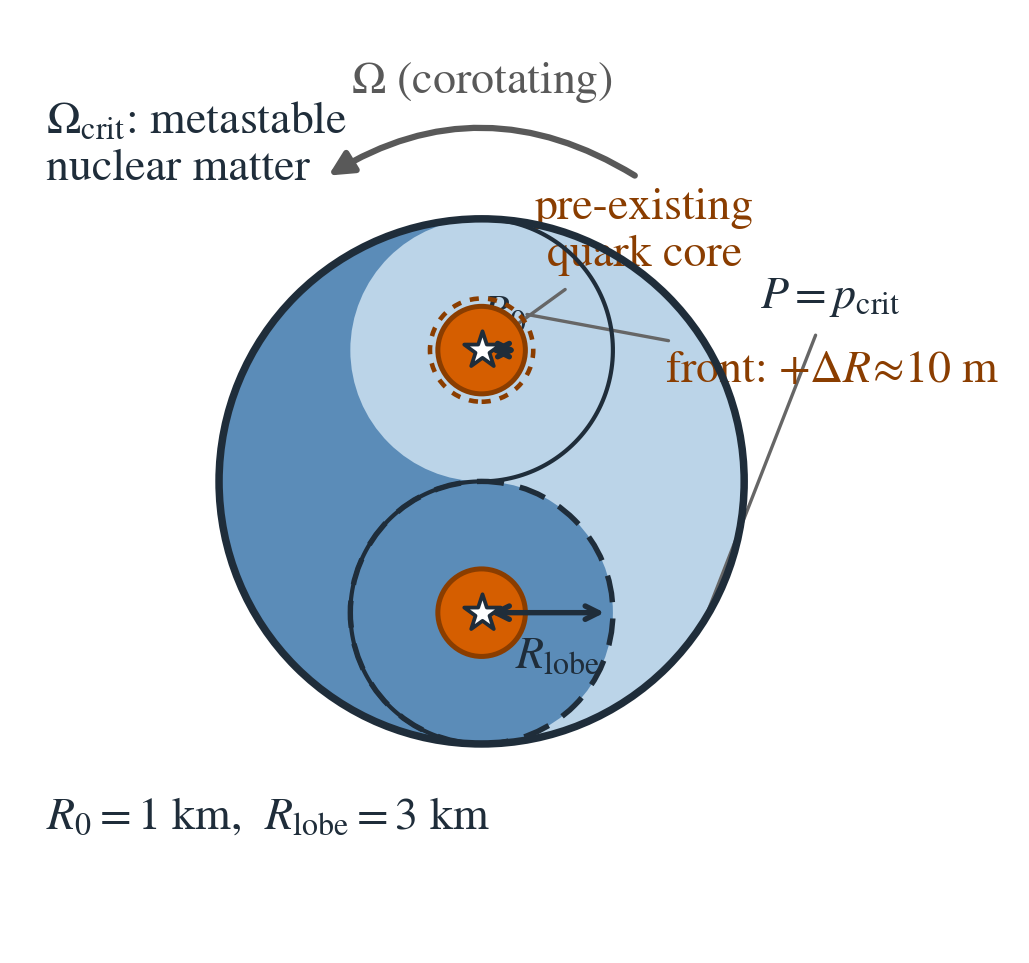

wrote omega_crit_taiji to Latex_writting/Hydrodynamical combustion/Plots, Latex_drop_in_integrated/v2/Plots


In [13]:
# Omega_crit geometry illustration (2D taiji), pre-existing-core picture:
# R_0 = 1 km cores inside R_lobe = 3 km lobes; front advances ~10 m per window.
# Fonts >= 11 pt at 3.4 in width for 1:1 columnwidth insertion.
# Run from the repo root; writes to both Plots dirs.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Wedge, FancyArrowPatch

# Tunable plotting parameters
FIGURE_SIZE = (3.4, 3.8)
DPI = 300
FONT_FAMILY = "STIXGeneral"
MATH_FONTSET = "stix"
LABEL_FONT_SIZE = 11
ANNOT_FONT_SIZE = 11
R = 1.0                                 # taiji (Omega_crit equatorial) radius, schematic
R0_FRAC = 1.0 / 3.0                     # R_0 / R_lobe = 1 km / 3 km
RLOBE_FIG = 0.5 * R                     # visual lobe radius (= head circle radius)
R0_FIG = R0_FRAC * RLOBE_FIG            # visual pre-existing-core radius
FRONT_EXAG = 1.18                       # exaggeration of the ~1% front growth ring
LOBE_LIGHT = "#BBD4E8"
LOBE_DARK = "#5B8CB8"
OUTLINE_COLOR = "#1F2D3A"
OUTLINE_WIDTH = 1.8
CORE_COLOR = "#D55E00"                  # pre-existing quark core
CORE_EDGE = "#8A3D00"
FRONT_COLOR = "#8A3D00"
RLOBE_RING_COLOR = "#1F2D3A"
SEED_FACE = "#FFFFFF"
SEED_EDGE = "#1F2D3A"
SEED_SIZE = 85
SEED_TOP = (0.0, 0.5 * R)
SEED_BOT = (0.0, -0.5 * R)
ROT_COLOR = "0.35"
ROT_WIDTH = 1.5
DIM_COLOR = "#1F2D3A"
DIM_WIDTH = 1.3
LEADER_COLOR = "0.4"
LEADER_WIDTH = 0.8
AXIS_LIMIT = 1.72
OUTPUT_DIRS = ["Latex_writting/Hydrodynamical combustion/Plots", "Latex_drop_in_integrated/v2/Plots"]
OUTPUT_NAME = "omega_crit_taiji"

plt.rcParams.update({"font.family": FONT_FAMILY, "mathtext.fontset": MATH_FONTSET})

fig, ax = plt.subplots(figsize=FIGURE_SIZE, dpi=DPI)

# Taiji: base disk light, left half dark, bottom small disk dark, top small disk light.
ax.add_patch(Circle((0, 0), R, facecolor=LOBE_LIGHT, edgecolor="none", zorder=1))
ax.add_patch(Wedge((0, 0), R, 90, 270, facecolor=LOBE_DARK, edgecolor="none", zorder=2))
ax.add_patch(Circle((0, -0.5 * R), 0.5 * R, facecolor=LOBE_DARK, edgecolor="none", zorder=3))
ax.add_patch(Circle((0, 0.5 * R), 0.5 * R, facecolor=LOBE_LIGHT, edgecolor="none", zorder=3))
theta = np.linspace(0, np.pi, 100)
ax.plot(0.5 * R * np.sin(theta), 0.5 * R + 0.5 * R * np.cos(theta),
        color=OUTLINE_COLOR, lw=1.0, zorder=4)
ax.plot(-0.5 * R * np.sin(theta), -0.5 * R - 0.5 * R * np.cos(theta),
        color=OUTLINE_COLOR, lw=1.0, zorder=4)
ax.add_patch(Circle((0, 0), R, facecolor="none", edgecolor=OUTLINE_COLOR,
                    lw=OUTLINE_WIDTH, zorder=5))

# R_lobe indicator ring around the bottom lobe
ax.add_patch(Circle(SEED_BOT, RLOBE_FIG, facecolor="none", edgecolor=RLOBE_RING_COLOR,
                    lw=DIM_WIDTH, ls=(0, (5, 3)), zorder=5))

# Exaggerated front-growth ring around the top core
ax.add_patch(Circle(SEED_TOP, R0_FIG * FRONT_EXAG, facecolor="none", edgecolor=FRONT_COLOR,
                    lw=1.1, ls=(0, (2, 2)), zorder=6))

# Pre-existing quark cores
for c in (SEED_TOP, SEED_BOT):
    ax.add_patch(Circle(c, R0_FIG, facecolor=CORE_COLOR, edgecolor=CORE_EDGE, lw=1.2, zorder=7))
    ax.scatter(*c, marker="*", s=SEED_SIZE, facecolor=SEED_FACE, edgecolor=SEED_EDGE,
               linewidth=0.9, zorder=8)

# R_0 dimension arrow on the top core
ax.add_patch(FancyArrowPatch(SEED_TOP, (R0_FIG, SEED_TOP[1]), arrowstyle="<->",
                             mutation_scale=8, lw=DIM_WIDTH, color=DIM_COLOR, zorder=9))
ax.text(R0_FIG * 0.5, SEED_TOP[1] + 0.055, r"$R_0$", fontsize=ANNOT_FONT_SIZE,
        color=DIM_COLOR, ha="center", va="bottom")
# R_lobe dimension arrow on the bottom lobe
ax.add_patch(FancyArrowPatch(SEED_BOT, (RLOBE_FIG, SEED_BOT[1]), arrowstyle="<->",
                             mutation_scale=8, lw=DIM_WIDTH, color=DIM_COLOR, zorder=9))
ax.text(RLOBE_FIG * 0.58, SEED_BOT[1] - 0.09, r"$R_{\rm lobe}$", fontsize=ANNOT_FONT_SIZE,
        color=DIM_COLOR, ha="center", va="top")

# Corotation arrow
ax.add_patch(FancyArrowPatch(
    (1.30 * R * np.cos(np.deg2rad(62)), 1.30 * R * np.sin(np.deg2rad(62))),
    (1.30 * R * np.cos(np.deg2rad(118)), 1.30 * R * np.sin(np.deg2rad(118))),
    connectionstyle="arc3,rad=0.32", arrowstyle="-|>", mutation_scale=12,
    lw=ROT_WIDTH, color=ROT_COLOR, zorder=6))
ax.text(0, 1.52 * R, r"$\Omega$ (corotating)", fontsize=ANNOT_FONT_SIZE,
        color=ROT_COLOR, ha="center", va="center")

# Labels with leader lines
ax.text(-1.66 * R, 1.28 * R, r"$\Omega_{\rm crit}$: metastable" + "\n" + r"nuclear matter",
        fontsize=LABEL_FONT_SIZE, color=OUTLINE_COLOR, ha="left", va="center")
ax.annotate(r"$P=p_{\rm crit}$", xy=(R * np.cos(np.deg2rad(-32)), R * np.sin(np.deg2rad(-32))),
            xytext=(1.06 * R, 0.70 * R), fontsize=ANNOT_FONT_SIZE, color=OUTLINE_COLOR,
            ha="left", va="center",
            arrowprops=dict(arrowstyle="-", color=LEADER_COLOR, lw=LEADER_WIDTH))
ax.annotate("pre-existing\nquark core", xy=SEED_TOP,
            xytext=(0.62 * R, 0.95 * R), fontsize=ANNOT_FONT_SIZE, color=CORE_EDGE,
            ha="center", va="center",
            arrowprops=dict(arrowstyle="-", color=LEADER_COLOR, lw=LEADER_WIDTH))
ax.annotate(r"front: $+\Delta R\!\approx\!10$ m", xy=(R0_FIG * FRONT_EXAG * 0.72, SEED_TOP[1] + R0_FIG * FRONT_EXAG * 0.72),
            xytext=(0.70 * R, 0.42 * R), fontsize=ANNOT_FONT_SIZE, color=FRONT_COLOR,
            ha="left", va="center",
            arrowprops=dict(arrowstyle="-", color=LEADER_COLOR, lw=LEADER_WIDTH))
ax.text(-1.66 * R, -1.28 * R, r"$R_0=1$ km,  $R_{\rm lobe}=3$ km",
        fontsize=ANNOT_FONT_SIZE, color=DIM_COLOR, ha="left", va="center")

ax.set_xlim(-AXIS_LIMIT, AXIS_LIMIT)
ax.set_ylim(-AXIS_LIMIT, AXIS_LIMIT)
ax.set_aspect("equal")
ax.axis("off")

fig.tight_layout(pad=0.2)
for d in OUTPUT_DIRS:
    fig.savefig(f"{d}/{OUTPUT_NAME}.pdf"); fig.savefig(f"{d}/{OUTPUT_NAME}.png")
plt.show()
print("wrote " + OUTPUT_NAME + " to " + ", ".join(OUTPUT_DIRS))

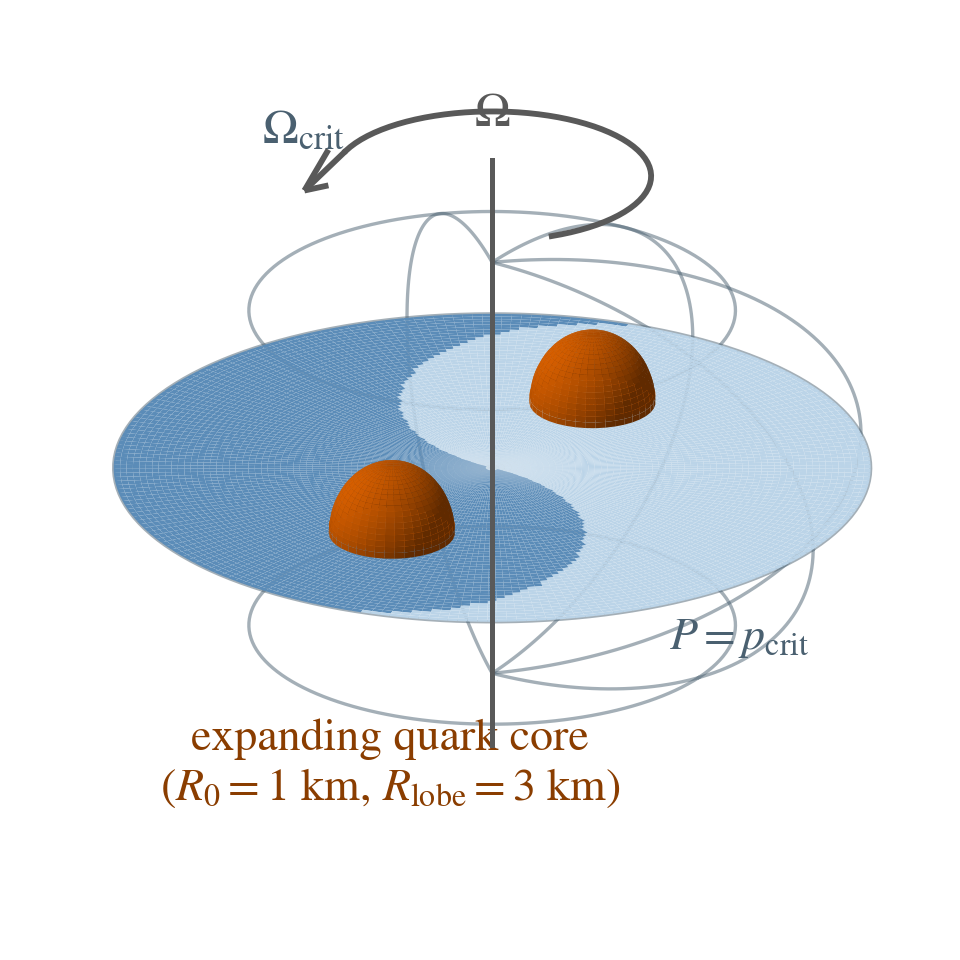

wrote omega_crit_taiji_3d to Latex_writting/Hydrodynamical combustion/Plots, Latex_drop_in_integrated/v2/Plots


In [14]:
# Omega_crit geometry illustration (3D), pre-existing-core picture: two R_0 = 1 km
# quark-core domes (drawn to scale, R_0/R_lobe = 1/3) inside the oblate p_crit cage.
# Fonts >= 11 pt for 1:1 columnwidth insertion (bbox tight).
# Run from the repo root; writes to both Plots dirs.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba

# Tunable plotting parameters
FIGURE_SIZE = (3.0, 3.0)
DPI = 300
AXES_BOUNDS = (0.0, 0.0, 1.0, 1.0)
PROJECTION_ZOOM = 1.45
SAVE_PADDING_INCHES = 0.01
FONT_FAMILY = "STIXGeneral"
MATH_FONTSET = "stix"
LABEL_FONT_SIZE = 11.5
ANNOT_FONT_SIZE = 11
VIEW_ELEV = 24
VIEW_AZIM = -58
R = 1.0                     # equatorial radius of Omega_crit
C = 0.5 * R                 # polar semi-axis (oblate: C < R)
LOBE_LIGHT = "#BBD4E8"
LOBE_DARK = "#5B8CB8"
SHELL_COLOR = "#4A6070"
SHELL_ALPHA = 0.5
SHELL_WIDTH = 0.8
QUARK_COLOR = "#D55E00"
SEED_COLOR = "#1F2D3A"
R_CONV = 0.5 * R / 3.0      # pre-existing quark-core radius, true scale:
                            # R_0/R_lobe = 1/3 with lobe radius 0.5*R
SEED_TOP = (0.0, 0.5 * R)
SEED_BOT = (0.0, -0.5 * R)
AXIS_COLOR = "0.35"
N_DISK_R = 60
N_DISK_PHI = 240
N_SPHERE = 40
N_SHELL = 22
OUTPUT_DIRS = ["Latex_writting/Hydrodynamical combustion/Plots", "Latex_drop_in_integrated/v2/Plots"]
OUTPUT_NAME = "omega_crit_taiji_3d"

plt.rcParams.update({"font.family": FONT_FAMILY, "mathtext.fontset": MATH_FONTSET})


def lobe_is_light(x, y):
    """Taiji rule: which lobe (True = light) a point in the equatorial plane is in."""
    top = x**2 + (y - 0.5 * R) ** 2 < (0.5 * R) ** 2
    bot = x**2 + (y + 0.5 * R) ** 2 < (0.5 * R) ** 2
    light = np.where(x >= 0, True, False)   # right half light, left half dark
    light = np.where(top, True, light)      # top small disk -> light
    light = np.where(bot, False, light)     # bottom small disk -> dark
    return light


fig = plt.figure(figsize=FIGURE_SIZE, dpi=DPI)
ax = fig.add_subplot(111, projection="3d")
ax.set_proj_type("ortho")
ax.computed_zorder = False   # honor manual zorder so domes draw over the disk

# Equatorial taiji disk at z = 0
rr = np.linspace(0, R, N_DISK_R)
pp = np.linspace(0, 2 * np.pi, N_DISK_PHI)
Rr, Pp = np.meshgrid(rr, pp)
Xd = Rr * np.cos(Pp)
Yd = Rr * np.sin(Pp)
Zd = np.zeros_like(Xd)
light = lobe_is_light(Xd, Yd)
facecolors = np.where(light[..., None],
                      np.array(to_rgba(LOBE_LIGHT)),
                      np.array(to_rgba(LOBE_DARK)))
ax.plot_surface(Xd, Yd, Zd, facecolors=facecolors, shade=False,
                rstride=1, cstride=1, linewidth=0, antialiased=True, zorder=2)

# Oblate p_crit shell as a sparse cage of rings (boundary without muddying interior)
th = np.linspace(0, np.pi, 120)
for phi0 in np.deg2rad([0, 45, 90, 135]):          # meridians
    ax.plot(R * np.sin(th) * np.cos(phi0), R * np.sin(th) * np.sin(phi0),
            C * np.cos(th), color=SHELL_COLOR, alpha=SHELL_ALPHA,
            lw=SHELL_WIDTH, zorder=1)
phc = np.linspace(0, 2 * np.pi, 160)
for th0 in np.deg2rad([40, 90, 140]):              # latitude rings
    ax.plot(R * np.sin(th0) * np.cos(phc), R * np.sin(th0) * np.sin(phc),
            C * np.cos(th0) * np.ones_like(phc), color=SHELL_COLOR,
            alpha=SHELL_ALPHA, lw=SHELL_WIDTH, zorder=1)

# Converted quark region: red equatorial slice + shaded upper dome. The dome
# sits entirely above z=0, so it never intersects the disk (avoids mplot3d's
# occlusion bug) yet reads as a sphere half-embedded in the equatorial cut.
uu = np.linspace(0, 2 * np.pi, N_SPHERE)
vv = np.linspace(0, np.pi / 2, N_SPHERE // 2)     # upper hemisphere only
nx = np.outer(np.cos(uu), np.sin(vv))
ny = np.outer(np.sin(uu), np.sin(vv))
nz = np.outer(np.ones_like(uu), np.cos(vv))
light = np.array([-0.5, -0.4, 0.77])
light = light / np.linalg.norm(light)
intensity = np.clip(nx * light[0] + ny * light[1] + nz * light[2], 0, 1)
shade = 0.45 + 0.55 * intensity
base = np.array(to_rgba(QUARK_COLOR))
dome_colors = np.empty(nx.shape + (4,))
dome_colors[..., :3] = base[:3] * shade[..., None]
dome_colors[..., 3] = 1.0
rs = np.linspace(0, R_CONV, 8)
ps = np.linspace(0, 2 * np.pi, N_SPHERE)
Rs, Ps = np.meshgrid(rs, ps)
Xsl, Ysl = Rs * np.cos(Ps), Rs * np.sin(Ps)
for (cx, cy) in (SEED_TOP, SEED_BOT):
    ax.plot_surface(Xsl + cx, Ysl + cy, np.full_like(Xsl, 0.02), color=QUARK_COLOR,
                    shade=False, rstride=1, cstride=1, linewidth=0, zorder=4)
    ax.plot_surface(R_CONV * nx + cx, R_CONV * ny + cy, R_CONV * nz,
                    facecolors=dome_colors, shade=False, rstride=1, cstride=1,
                    linewidth=0, antialiased=True, zorder=6)
#ax.scatter([SEED_TOP[0]], [SEED_TOP[1]], [R_CONV], color=SEED_COLOR, marker="*",
#           s=70, depthshade=False, zorder=7)

# Rotation axis and Omega arrow
ax.plot([0, 0], [0, 0], [-1.35 * C, 1.5 * C], color=AXIS_COLOR, lw=1.2, zorder=4)
arc = np.linspace(-0.2 * np.pi, 1.05 * np.pi, 60)
ax.plot(0.42 * R * np.cos(arc), 0.42 * R * np.sin(arc),
        1.42 * C * np.ones_like(arc), color=AXIS_COLOR, lw=1.4, zorder=6)
ax.quiver(0.42 * R * np.cos(arc[-1]), 0.42 * R * np.sin(arc[-1]), 1.42 * C,
          -np.sin(arc[-1]), np.cos(arc[-1]), 0, length=0.28, color=AXIS_COLOR,
          arrow_length_ratio=0.6, lw=1.4, zorder=6)
ax.text(0, 0, 1.72 * C, r"$\Omega$", fontsize=LABEL_FONT_SIZE, color=AXIS_COLOR,
        ha="center", va="center")

# Labels
ax.text(-1.15 * R, 0.9 * R, 0.55 * C, r"$\Omega_{\rm crit}$", fontsize=LABEL_FONT_SIZE,
        color=SHELL_COLOR, ha="center")
ax.text(1.02 * R, -0.75 * R, 0.0, r"$P=p_{\rm crit}$", fontsize=ANNOT_FONT_SIZE,
        color=SHELL_COLOR, ha="left")
ax.text(SEED_BOT[0] + 0.15, SEED_BOT[1] - 0.25, -1.08 * C,
        "expanding quark core\n($R_0=1$ km, $R_{\\rm lobe}=3$ km)",
        fontsize=ANNOT_FONT_SIZE, color="#8A3D00", ha="center")
#ax.text(SEED_TOP[0] - 0.1, SEED_TOP[1] + 0.34, 0.55 * C, "seed:\npressure max",
#        fontsize=ANNOT_FONT_SIZE, color=SEED_COLOR, ha="center")

ax.view_init(elev=VIEW_ELEV, azim=VIEW_AZIM)
ax.set_box_aspect((1, 1, 0.62), zoom=PROJECTION_ZOOM)
ax.set_xlim(-1.15 * R, 1.15 * R)
ax.set_ylim(-1.15 * R, 1.15 * R)
ax.set_zlim(-1.2 * C, 1.2 * C)
ax.set_axis_off()

ax.set_position(AXES_BOUNDS)
for d in OUTPUT_DIRS:
    fig.savefig(f"{d}/{OUTPUT_NAME}.pdf", bbox_inches="tight", pad_inches=SAVE_PADDING_INCHES)
    fig.savefig(f"{d}/{OUTPUT_NAME}.png", bbox_inches="tight", pad_inches=SAVE_PADDING_INCHES)
plt.show()
print("wrote " + OUTPUT_NAME + " to " + ", ".join(OUTPUT_DIRS))